In [2]:
%pip install "mne==1.10.2" "scipy==1.13.1"

  Using cached scipy-1.13.1-cp312-cp312-macosx_12_0_arm64.whl.metadata (60 kB)
  Using cached numpy-2.2.6-cp312-cp312-macosx_14_0_arm64.whl.metadata (62 kB)
Using cached scipy-1.13.1-cp312-cp312-macosx_12_0_arm64.whl (30.4 MB)
Using cached numpy-2.2.6-cp312-cp312-macosx_14_0_arm64.whl (5.1 MB)
  Attempting uninstall: numpy
    Found existing installation: numpy 2.5.4
    Uninstalling numpy-2.5.4:
      Successfully uninstalled numpy-2.5.4
  Attempting uninstall: scipy
    Found existing installation: scipy 1.18.1
    Uninstalling scipy-1.18.1:
      Successfully uninstalled scipy-1.18.1

[notice] A new release of pip is available: 24.2 -> 26.2.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [3]:
import mne
from mne.datasets import eegbci

files = eegbci.load_data(
    1,
    runs=[1],
    path="./eeg_data",
    update_path=False
)

raw = mne.io.read_raw_edf(files[0], preload=True)

eegbci.standardize(raw)

Download complete in 01m11s (1.2 MB)
Extracting EDF parameters from /Users/Novichkov/mathstats/eeg_data/MNE-eegbci-data/files/eegmmidb/1.0.0/S001/S001R01.edf...
EDF file detected
Setting channel info structure...
Creating raw.info structure...
Reading 0 ... 9759  =      0.000 ...    60.994 secs...


In [4]:
raw.ch_names

['FC5',
 'FC3',
 'FC1',
 'FCz',
 'FC2',
 'FC4',
 'FC6',
 'C5',
 'C3',
 'C1',
 'Cz',
 'C2',
 'C4',
 'C6',
 'CP5',
 'CP3',
 'CP1',
 'CPz',
 'CP2',
 'CP4',
 'CP6',
 'Fp1',
 'Fpz',
 'Fp2',
 'AF7',
 'AF3',
 'AFz',
 'AF4',
 'AF8',
 'F7',
 'F5',
 'F3',
 'F1',
 'Fz',
 'F2',
 'F4',
 'F6',
 'F8',
 'FT7',
 'FT8',
 'T7',
 'T8',
 'T9',
 'T10',
 'TP7',
 'TP8',
 'P7',
 'P5',
 'P3',
 'P1',
 'Pz',
 'P2',
 'P4',
 'P6',
 'P8',
 'PO7',
 'PO3',
 'POz',
 'PO4',
 'PO8',
 'O1',
 'Oz',
 'O2',
 'Iz']

Нашли библиотеку с ЭЭГ, скачаем данные по 6и каналам

In [5]:
import numpy as np
my_channels = ["F3", "F4", "C3", "C4", "C5", "P3", "P4"]

X = raw.get_data(picks=my_channels).T

print("Размер:", X.shape)
print("Частота:", raw.info["sfreq"], "Гц")
print("Стандартные отклонения:", X.std(axis=0))


Размер: (9760, 7)
Частота: 160.0 Гц
Стандартные отклонения: [6.31835827e-05 5.82177727e-05 5.16936733e-05 4.56638130e-05
 5.36417130e-05 5.16457119e-05 4.74359473e-05]


Будем использовать уже готовые модели VARLINGAM и PCMCI+ c проверкой корелляции ParCorr

In [6]:
%pip install lingam tigramite


[notice] A new release of pip is available: 24.2 -> 26.2.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [7]:
import mne
from lingam import VARLiNGAM
from tigramite import data_processing as pp
from tigramite.pcmci import PCMCI
from tigramite.independence_tests.parcorr import ParCorr

Скачаем NOTEARS для линейных моделей

In [8]:
%pip install "https://github.com/xunzheng/notears/archive/refs/heads/master.zip" "scipy==1.13.1"

  Using cached https://github.com/xunzheng/notears/archive/refs/heads/master.zip
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done

[notice] A new release of pip is available: 24.2 -> 26.2.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [9]:
from notears.linear import notears_linear

Давайте натренируем наши модели

In [10]:
model_varlingam = VARLiNGAM(
    lags=2,
    criterion=None,
    prune=True,
    random_state=42
)

model_varlingam.fit(X)

data = pp.DataFrame(X.copy(), var_names=my_channels)

model_pcmci = PCMCI(
    dataframe=data,
    cond_ind_test=ParCorr(significance="analytic"),
    verbosity=0
)

results_pcmci = model_pcmci.run_pcmciplus(
    tau_min=0,
    tau_max=2,
    pc_alpha=0.05
)

X_std = (X - X.mean(axis=0)) / X.std(axis=0)

W_notears = notears_linear(
    X_std.copy(),
    lambda1=0.05,
    loss_type="l2",
    w_threshold=0.1
)

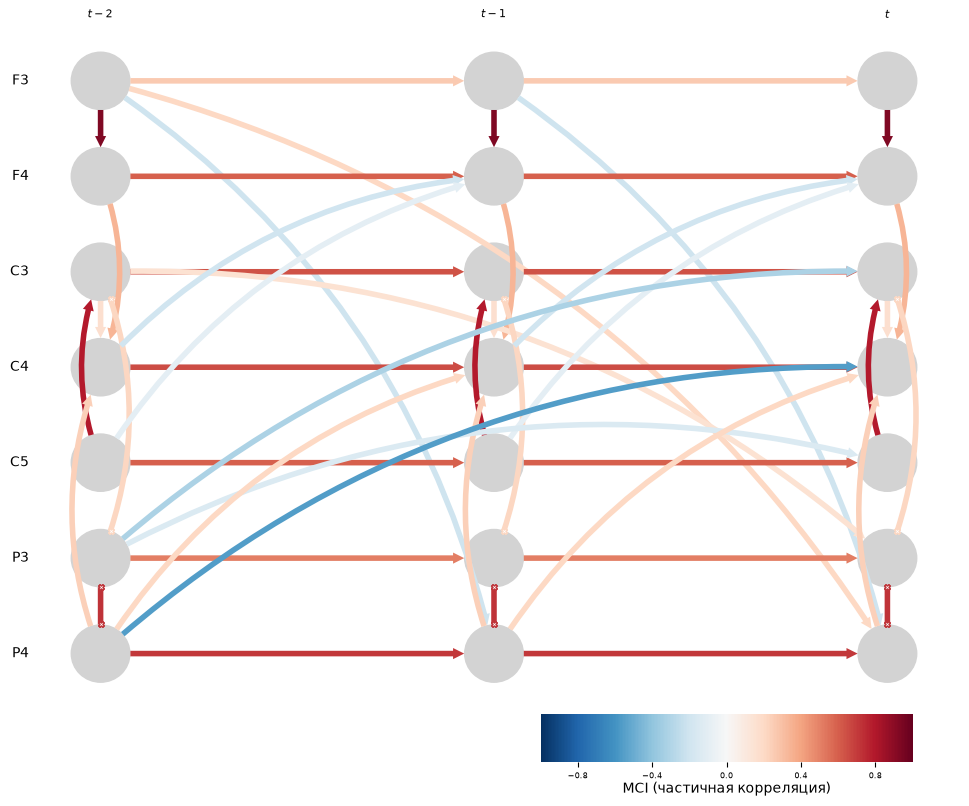

In [11]:
import numpy as np
import matplotlib.pyplot as plt
import tigramite.plotting as tp

threshold = 0.1

graph_plot = results_pcmci["graph"].copy()
graph_plot[np.abs(results_pcmci["val_matrix"]) < threshold] = ""

tp.plot_time_series_graph(
    graph=graph_plot,
    val_matrix=results_pcmci["val_matrix"],
    var_names=my_channels,
    link_colorbar_label="MCI (частичная корреляция)",
    figsize=(12, 9)
)
plt.show()

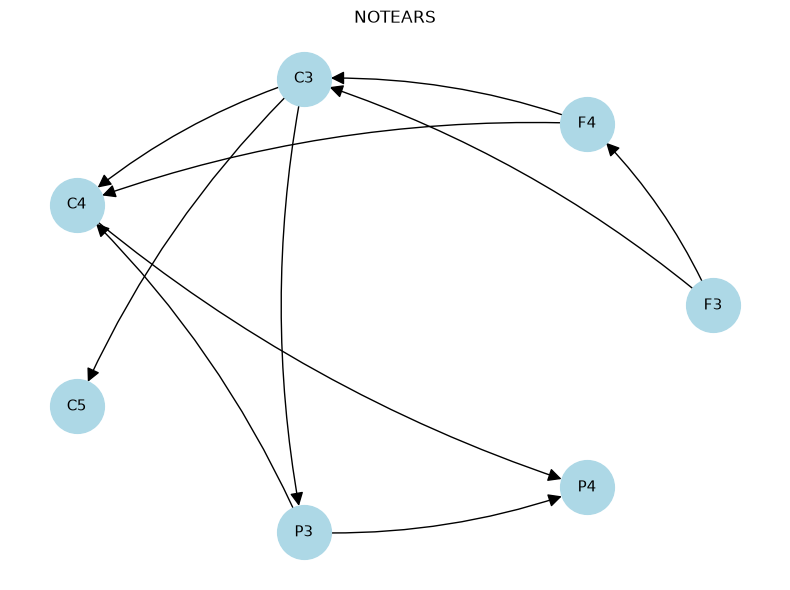

In [12]:
import networkx as nx

G = nx.from_numpy_array(W_notears, create_using=nx.DiGraph)

labels = dict(enumerate(my_channels))
pos = nx.circular_layout(G)

plt.figure(figsize=(8, 6))

nx.draw_networkx(
    G,
    pos,
    labels=labels,
    node_color="lightblue",
    node_size=1500,
    arrowsize=20,
    font_size=11,
    connectionstyle="arc3,rad=0.1"
)

plt.title("NOTEARS")
plt.axis("off")
plt.tight_layout()
plt.show()

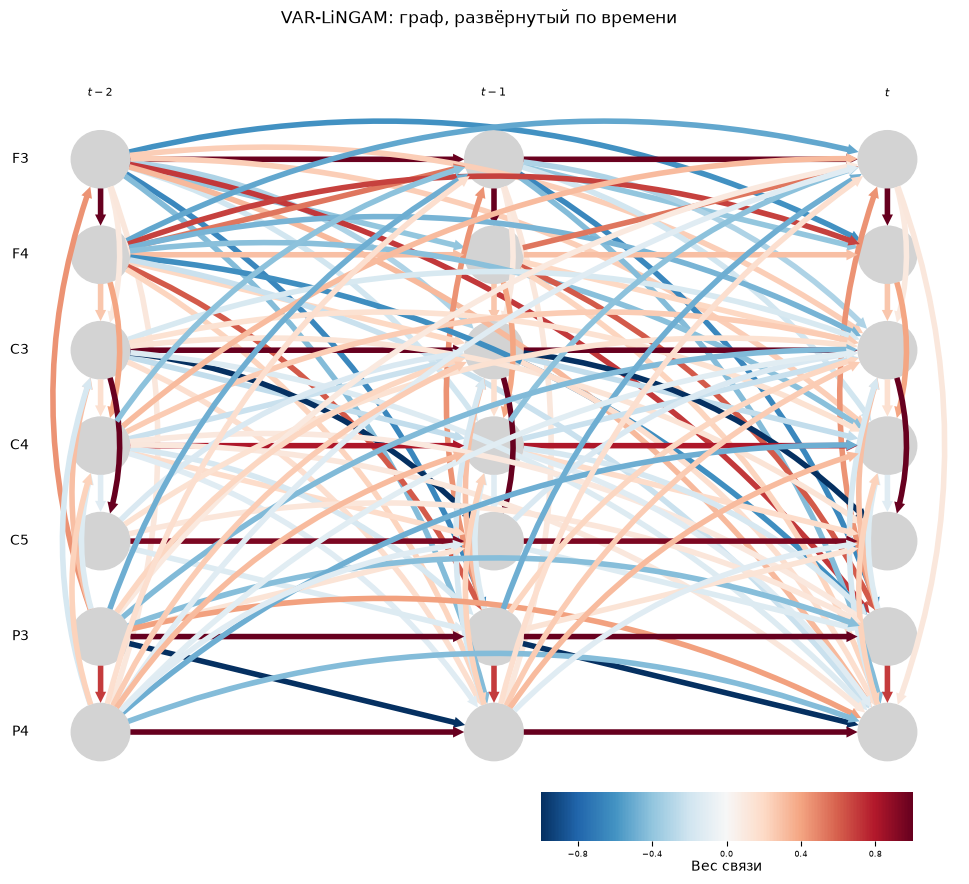

In [13]:
def to_tigramite(matrices, threshold=0.1):
    # matrices[tau][i, j] — влияние канала i в момент t - tau на канал j в момент t
    n = matrices[0].shape[0]
    graph = np.full((n, n, len(matrices)), "", dtype="<U3")
    val_matrix = np.zeros((n, n, len(matrices)))
    for tau in range(len(matrices)):
        for i in range(n):
            for j in range(n):
                w = matrices[tau][i, j]
                if abs(w) < threshold or (tau == 0 and i == j):
                    continue
                if tau == 0:
                    graph[i, j, 0] = "-->"
                    graph[j, i, 0] = "<--"
                    val_matrix[i, j, 0] = w
                    val_matrix[j, i, 0] = w
                else:
                    graph[i, j, tau] = "-->"
                    val_matrix[i, j, tau] = w
    return graph, val_matrix

B = model_varlingam.adjacency_matrices_

varlingam_matrices = [B[tau].T for tau in range(B.shape[0])]
graph_varlingam, val_varlingam = to_tigramite(varlingam_matrices)

tp.plot_time_series_graph(
    graph=graph_varlingam,
    val_matrix=val_varlingam,
    var_names=my_channels,
    link_colorbar_label="Вес связи",
    figsize=(12, 9)
)
plt.suptitle("VAR-LiNGAM: граф, развёрнутый по времени")
plt.show()


VARLiNGAM: число ребер = [61, 56, 59, 60, 65, 63, 66]
VARLiNGAM: Жаккар соседних префиксов = [0.67 0.69 0.95 0.52 0.94 0.95]
PCMCI+: число ребер = [14, 15, 11, 11, 15, 14, 14]
PCMCI+: Жаккар соседних префиксов = [0.45 0.53 0.83 0.37 0.38 0.56]
NOTEARS: число ребер = [10, 12, 12, 10, 8, 9, 10]
NOTEARS: Жаккар соседних префиксов = [0.38 0.5  0.83 0.8  0.89 0.9 ]


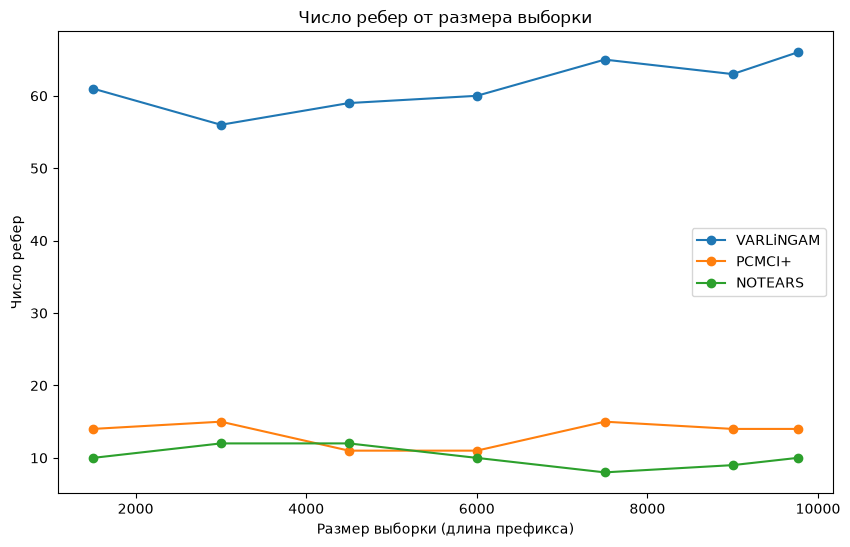

VARLiNGAM:
  n = 1500: F3 -> F4 -> P3 -> P4 -> C4 -> C5 -> C3
  n = 3000: P4 -> P3 -> F3 -> F4 -> C4 -> C5 -> C3
  n = 4500: F3 -> F4 -> P3 -> P4 -> C4 -> C5 -> C3
  n = 6000: F3 -> F4 -> P3 -> P4 -> C4 -> C5 -> C3
  n = 7500: P3 -> F3 -> F4 -> P4 -> C3 -> C4 -> C5
  n = 9000: P3 -> F3 -> F4 -> P4 -> C3 -> C4 -> C5
  n = 9760: P3 -> F3 -> F4 -> P4 -> C3 -> C4 -> C5
PCMCI+:
  n = 1500: F4 -> F3 -> C4 -> P3 -> C3 -> C5 -> P4
  n = 3000: F4 -> C5 -> P3 -> F3 -> C3 -> P4 -> C4
  n = 4500: F4 -> F3 -> C4 -> C5 -> P3 -> C3 -> P4
  n = 6000: F4 -> F3 -> C4 -> C5 -> C3 -> P3 -> P4
  n = 7500: F3 -> F4 -> C4 -> P3 -> C3 -> C5 -> P4
  n = 9000: F4 -> F3 -> C4 -> C5 -> C3 -> P3 -> P4
  n = 9760: F3 -> F4 -> C5 -> C3 -> P3 -> P4 -> C4
NOTEARS:
  n = 1500: F3 -> F4 -> C3 -> C5 -> P3 -> C4 -> P4
  n = 3000: P3 -> C4 -> F3 -> F4 -> C3 -> C5 -> P4
  n = 4500: F3 -> F4 -> C3 -> C5 -> P3 -> C4 -> P4
  n = 6000: F3 -> F4 -> C3 -> C5 -> P3 -> C4 -> P4
  n = 7500: F3 -> F4 -> C3 -> C4 -> C5 -> P3 -> P4
  n

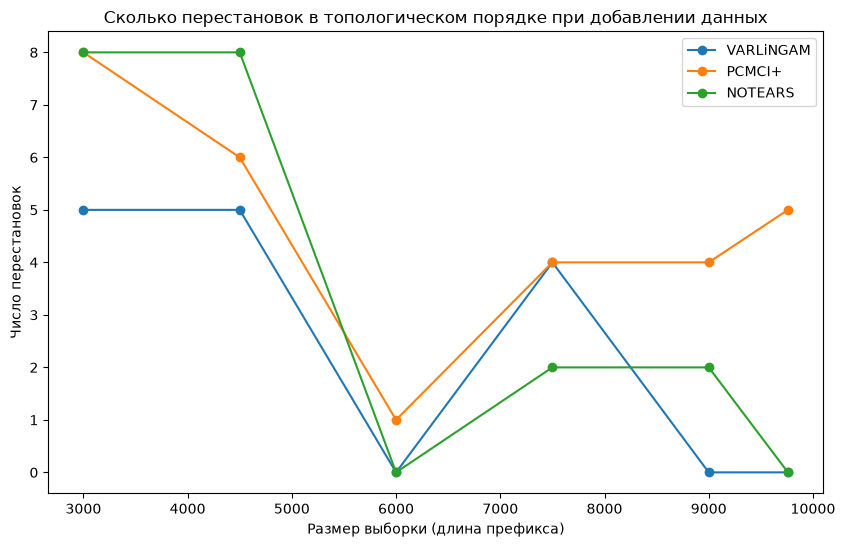

In [14]:
import networkx as nx

sizes = [1500, 3000, 4500, 6000, 7500, 9000, X.shape[0]]
threshold = 0.1

# Ребро — тройка (откуда, куда, лаг). Петли (канал сам на себя) не учитываем
def edges_varlingam(X_part):
    model = VARLiNGAM(lags=2, criterion=None, prune=True, random_state=42)
    model.fit(X_part)
    B_part = model.adjacency_matrices_
    edges = set()
    for lag, i, j in np.argwhere(np.abs(B_part) >= threshold):
        if i != j:
            edges.add((my_channels[j], my_channels[i], int(lag)))
    return edges

def edges_pcmci(X_part):
    data_part = pp.DataFrame(X_part.copy(), var_names=my_channels)
    model = PCMCI(dataframe=data_part, cond_ind_test=ParCorr(significance="analytic"), verbosity=0)
    results = model.run_pcmciplus(tau_min=0, tau_max=2, pc_alpha=0.05)
    edges = set()
    for i, j, lag in np.argwhere((results["graph"] == "-->") & (np.abs(results["val_matrix"]) >= threshold)):
        if i != j:
            edges.add((my_channels[i], my_channels[j], int(lag)))
    return edges

def edges_notears(X_part):
    X_part_std = (X_part - X_part.mean(axis=0)) / X_part.std(axis=0)
    W = notears_linear(X_part_std.copy(), lambda1=0.05, loss_type="l2", w_threshold=threshold)
    edges = set()
    for i, j in np.argwhere(W != 0):
        edges.add((my_channels[i], my_channels[j], 0))
    return edges

models = {"VARLiNGAM": edges_varlingam, "PCMCI+": edges_pcmci, "NOTEARS": edges_notears}

all_edges = {}
for name in models:
    all_edges[name] = [models[name](X[:n]) for n in sizes]

def jaccard(a, b):
    if len(a | b) == 0:
        return 1.0
    return len(a & b) / len(a | b)

for name in models:
    jaccards = [jaccard(all_edges[name][k], all_edges[name][k + 1]) for k in range(len(sizes) - 1)]
    print(f"{name}: число ребер = {[len(e) for e in all_edges[name]]}")
    print(f"{name}: Жаккар соседних префиксов = {np.round(jaccards, 2)}")

plt.figure(figsize=(10, 6))
for name in models:
    plt.plot(sizes, [len(e) for e in all_edges[name]], marker="o", label=name)
plt.xlabel("Размер выборки (длина префикса)")
plt.ylabel("Число ребер")
plt.title("Число ребер от размера выборки")
plt.legend()
plt.show()

# Топологическая сортировка мгновенной части графа (лаг 0), она должна быть ациклической
def topsort(edges):
    G = nx.DiGraph()
    G.add_nodes_from(my_channels)
    G.add_edges_from([(s, t) for s, t, lag in edges if lag == 0])
    if not nx.is_directed_acyclic_graph(G):
        return None
    return list(nx.lexicographical_topological_sort(G, key=my_channels.index))

# Число перестановок = сколько пар каналов поменяли взаимный порядок
def count_swaps(order1, order2):
    position = {v: k for k, v in enumerate(order2)}
    seq = [position[v] for v in order1]
    swaps = 0
    for a in range(len(seq)):
        for b in range(a + 1, len(seq)):
            if seq[a] > seq[b]:
                swaps += 1
    return swaps

all_swaps = {}
for name in models:
    orders = [topsort(e) for e in all_edges[name]]
    print(f"{name}:")
    for k in range(len(sizes)):
        if orders[k] is None:
            print(f"  n = {sizes[k]}: граф лага 0 с циклом")
        else:
            print(f"  n = {sizes[k]}: {' -> '.join(orders[k])}")
    all_swaps[name] = []
    for k in range(len(sizes) - 1):
        if orders[k] is None or orders[k + 1] is None:
            all_swaps[name].append(np.nan)
        else:
            all_swaps[name].append(count_swaps(orders[k], orders[k + 1]))

plt.figure(figsize=(10, 6))
for name in models:
    plt.plot(sizes[1:], all_swaps[name], marker="o", label=name)
plt.xlabel("Размер выборки (длина префикса)")
plt.ylabel("Число перестановок")
plt.title("Сколько перестановок в топологическом порядке при добавлении данных")
plt.legend()
plt.show()

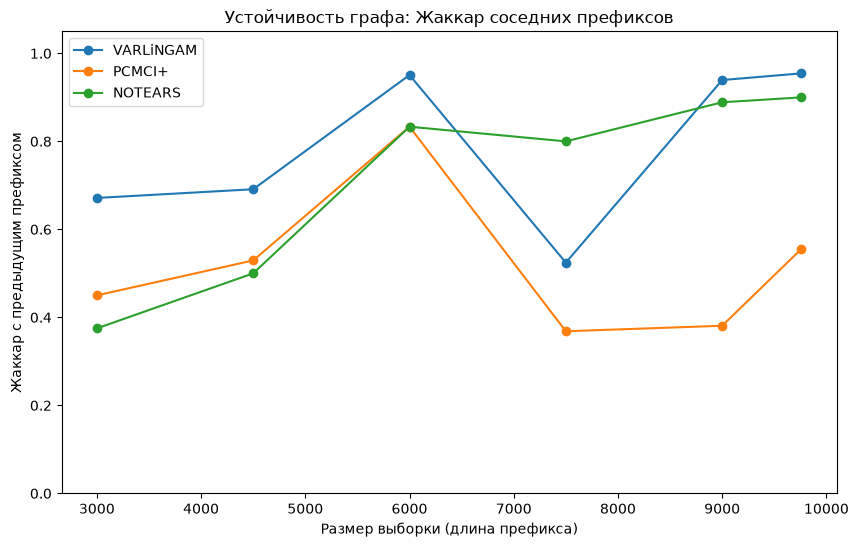

In [15]:
plt.figure(figsize=(10, 6))
for name in models:
    jaccards = [jaccard(all_edges[name][k], all_edges[name][k + 1]) for k in range(len(sizes) - 1)]
    plt.plot(sizes[1:], jaccards, marker="o", label=name)
plt.ylim(0, 1.05)
plt.xlabel("Размер выборки (длина префикса)")
plt.ylabel("Жаккар с предыдущим префиксом")
plt.title("Устойчивость графа: Жаккар соседних префиксов")
plt.legend()
plt.show()

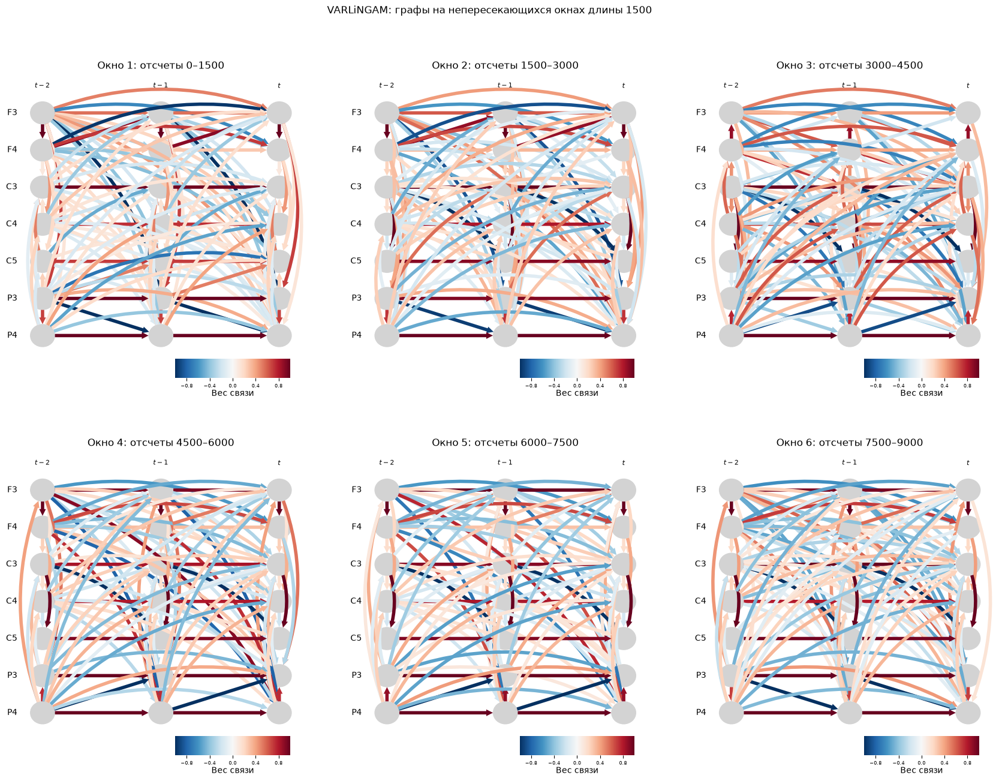

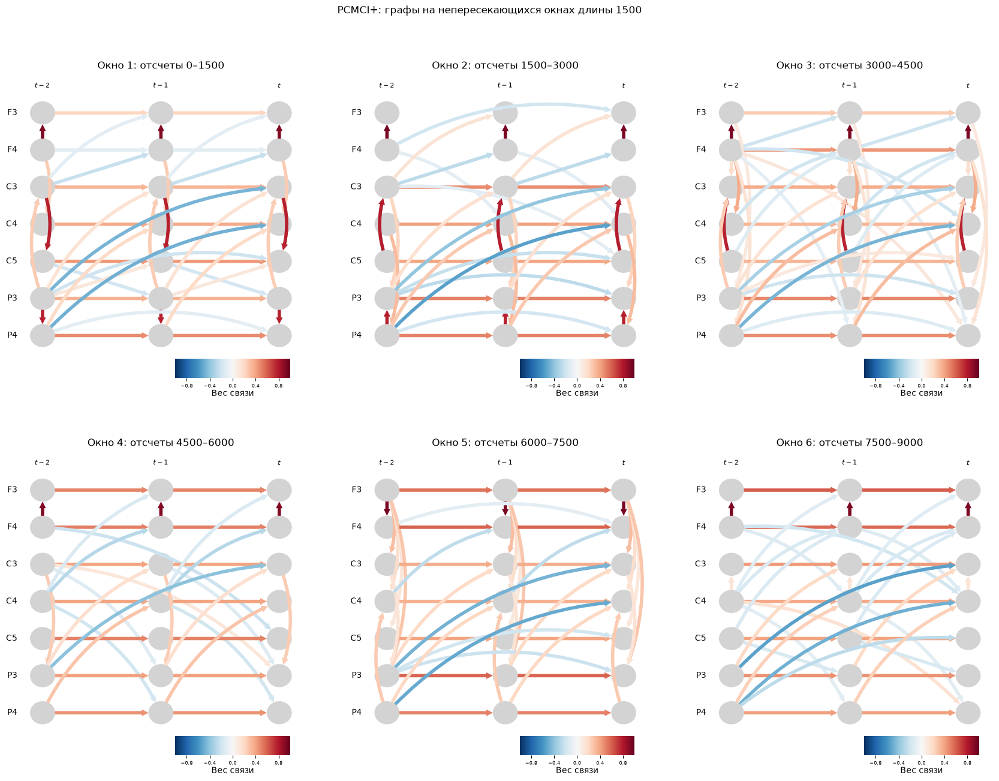

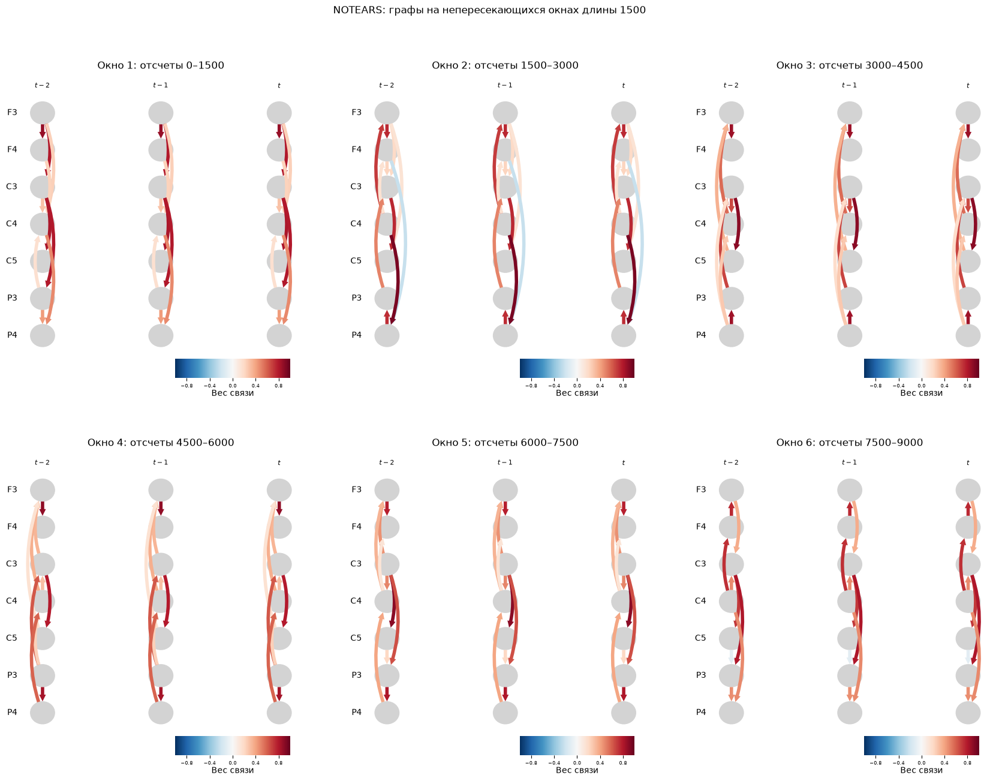

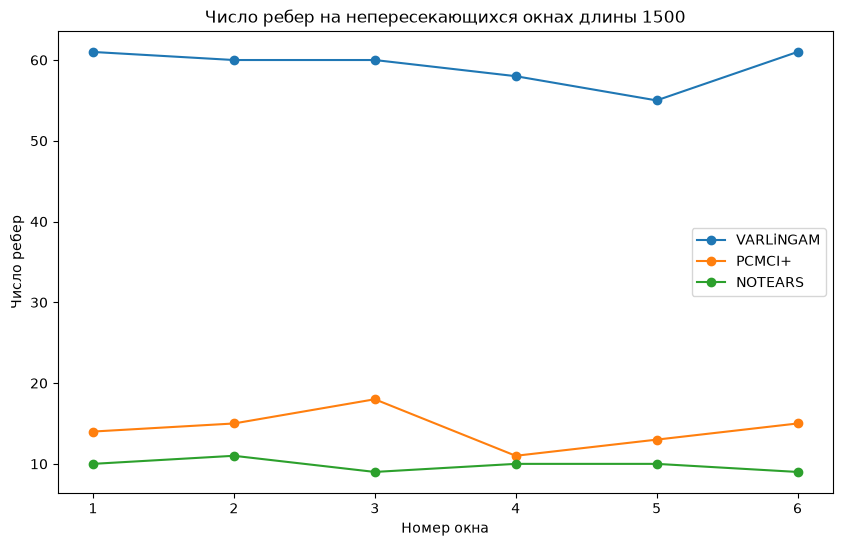

VARLiNGAM: число ребер = [61, 60, 60, 58, 55, 61]
VARLiNGAM: Жаккар соседних окон = [0.48 0.4  0.39 0.74 0.57]
PCMCI+: число ребер = [14, 15, 18, 11, 13, 15]
PCMCI+: Жаккар соседних окон = [0.38 0.27 0.21 0.26 0.22]
NOTEARS: число ребер = [10, 11, 9, 10, 10, 9]
NOTEARS: Жаккар соседних окон = [0.24 0.33 0.46 0.43 0.36]


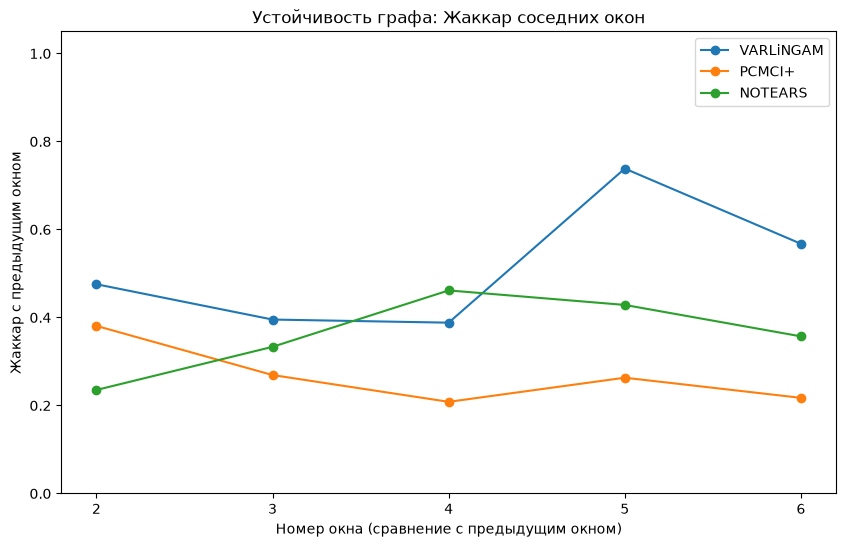

VARLiNGAM:
  окно 1: F3 -> F4 -> P3 -> P4 -> C4 -> C5 -> C3
  окно 2: F3 -> F4 -> C3 -> P3 -> P4 -> C4 -> C5
  окно 3: C3 -> C4 -> C5 -> P4 -> F4 -> F3 -> P3
  окно 4: P4 -> F3 -> F4 -> P3 -> C3 -> C4 -> C5
  окно 5: P4 -> P3 -> F3 -> F4 -> C3 -> C4 -> C5
  окно 6: P3 -> F3 -> F4 -> P4 -> C4 -> C3 -> C5
PCMCI+:
  окно 1: F4 -> F3 -> C4 -> P3 -> C3 -> C5 -> P4
  окно 2: F4 -> F3 -> C4 -> C5 -> C3 -> P4 -> P3
  окно 3: F4 -> F3 -> C4 -> C5 -> P3 -> C3 -> P4
  окно 4: F4 -> F3 -> C3 -> C4 -> C5 -> P3 -> P4
  окно 5: F3 -> F4 -> C3 -> C5 -> P3 -> P4 -> C4
  окно 6: F4 -> F3 -> C4 -> C3 -> C5 -> P3 -> P4
NOTEARS:
  окно 1: F3 -> F4 -> C3 -> C5 -> P3 -> C4 -> P4
  окно 2: C4 -> F3 -> F4 -> P4 -> P3 -> C3 -> C5
  окно 3: P4 -> P3 -> C3 -> C4 -> C5 -> F3 -> F4
  окно 4: P3 -> P4 -> C4 -> C3 -> C5 -> F3 -> F4
  окно 5: C3 -> C5 -> P3 -> P4 -> C4 -> F3 -> F4
  окно 6: C4 -> F4 -> F3 -> C3 -> C5 -> P3 -> P4


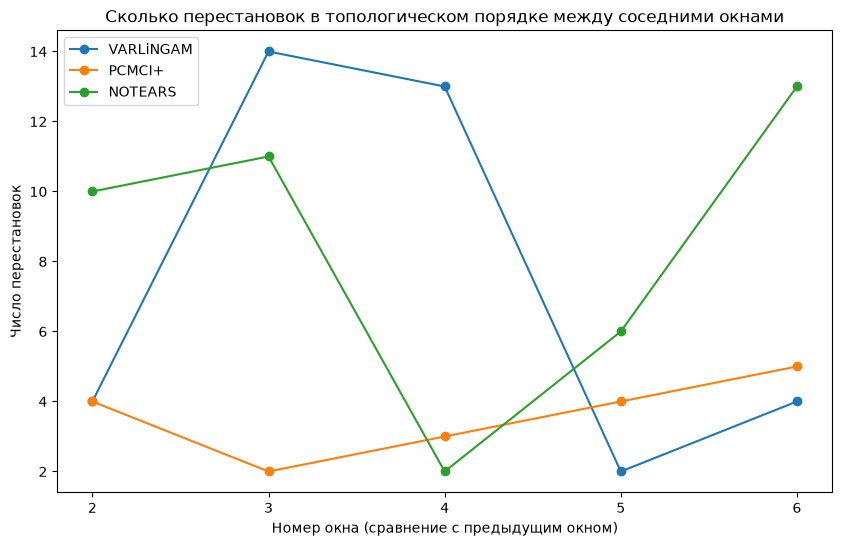

In [16]:
import networkx as nx

window = 1500
period = 1500
threshold = 0.1

# Непересекающиеся окна X[s : s + window], начало каждого следующего окна сдвинуто на period (period >= window)
starts = list(range(0, X.shape[0] - window + 1, period))
window_numbers = list(range(1, len(starts) + 1))

# matrices[tau][i, j] — влияние канала i в момент t - tau на канал j в момент t
def matrices_varlingam(X_part):
    model = VARLiNGAM(lags=2, criterion=None, prune=True, random_state=42)
    model.fit(X_part)
    B_part = model.adjacency_matrices_
    return [B_part[tau].T for tau in range(B_part.shape[0])]

def matrices_pcmci(X_part):
    data_part = pp.DataFrame(X_part.copy(), var_names=my_channels)
    model = PCMCI(dataframe=data_part, cond_ind_test=ParCorr(significance="analytic"), verbosity=0)
    results = model.run_pcmciplus(tau_min=0, tau_max=2, pc_alpha=0.05)
    M = np.where(results["graph"] == "-->", results["val_matrix"], 0)
    return [M[:, :, tau] for tau in range(M.shape[2])]

def matrices_notears(X_part):
    X_part_std = (X_part - X_part.mean(axis=0)) / X_part.std(axis=0)
    W = notears_linear(X_part_std.copy(), lambda1=0.05, loss_type="l2", w_threshold=threshold)
    return [W, np.zeros_like(W), np.zeros_like(W)]

# Ребро — тройка (откуда, куда, лаг). Петли не учитываем
def matrices_to_edges(matrices):
    edges = set()
    for tau in range(len(matrices)):
        for i, j in np.argwhere(np.abs(matrices[tau]) >= threshold):
            if i != j:
                edges.add((my_channels[i], my_channels[j], tau))
    return edges

window_models = {"VARLiNGAM": matrices_varlingam, "PCMCI+": matrices_pcmci, "NOTEARS": matrices_notears}

window_matrices = {name: [window_models[name](X[s:s + window]) for s in starts] for name in window_models}
window_edges = {name: [matrices_to_edges(M) for M in window_matrices[name]] for name in window_models}

# Графы на каждом окне
for name in window_models:
    n_rows = int(np.ceil(len(starts) / 3))
    fig, axes = plt.subplots(n_rows, 3, figsize=(21, 7 * n_rows))
    axes = np.array(axes).reshape(-1)
    for k in range(len(starts)):
        graph_k, val_k = to_tigramite(window_matrices[name][k], threshold)
        tp.plot_time_series_graph(
            graph=graph_k,
            val_matrix=val_k,
            var_names=my_channels,
            fig_ax=(fig, axes[k]),
            link_colorbar_label="Вес связи"
        )
        axes[k].set_title(f"Окно {k + 1}: отсчеты {starts[k]}–{starts[k] + window}", pad=25)
    for k in range(len(starts), len(axes)):
        axes[k].axis("off")
    fig.subplots_adjust(hspace=0.4)
    fig.suptitle(f"{name}: графы на непересекающихся окнах длины {window}")
    plt.show()

# Число ребер на каждом окне
plt.figure(figsize=(10, 6))
for name in window_models:
    plt.plot(window_numbers, [len(e) for e in window_edges[name]], marker="o", label=name)
plt.xticks(window_numbers)
plt.xlabel("Номер окна")
plt.ylabel("Число ребер")
plt.title(f"Число ребер на непересекающихся окнах длины {window}")
plt.legend()
plt.show()

# Жаккар соседних окон
window_jaccards = {}
for name in window_models:
    window_jaccards[name] = [jaccard(window_edges[name][k], window_edges[name][k + 1]) for k in range(len(starts) - 1)]
    print(f"{name}: число ребер = {[len(e) for e in window_edges[name]]}")
    print(f"{name}: Жаккар соседних окон = {np.round(window_jaccards[name], 2)}")

plt.figure(figsize=(10, 6))
for name in window_models:
    plt.plot(window_numbers[1:], window_jaccards[name], marker="o", label=name)
plt.ylim(0, 1.05)
plt.xticks(window_numbers[1:])
plt.xlabel("Номер окна (сравнение с предыдущим окном)")
plt.ylabel("Жаккар с предыдущим окном")
plt.title("Устойчивость графа: Жаккар соседних окон")
plt.legend()
plt.show()

# Топологическая сортировка графа лага 0 на каждом окне и число перестановок между соседними окнами
window_swaps = {}
for name in window_models:
    orders = [topsort(e) for e in window_edges[name]]
    print(f"{name}:")
    for k in range(len(starts)):
        if orders[k] is None:
            print(f"  окно {k + 1}: граф лага 0 с циклом")
        else:
            print(f"  окно {k + 1}: {' -> '.join(orders[k])}")
    window_swaps[name] = []
    for k in range(len(starts) - 1):
        if orders[k] is None or orders[k + 1] is None:
            window_swaps[name].append(np.nan)
        else:
            window_swaps[name].append(count_swaps(orders[k], orders[k + 1]))

plt.figure(figsize=(10, 6))
for name in window_models:
    plt.plot(window_numbers[1:], window_swaps[name], marker="o", label=name)
plt.xticks(window_numbers[1:])
plt.xlabel("Номер окна (сравнение с предыдущим окном)")
plt.ylabel("Число перестановок")
plt.title("Сколько перестановок в топологическом порядке между соседними окнами")
plt.legend()
plt.show()

ВЫВОДЫ:

Я скачал данные ЭЭГ из библиотеки MNE. И рассматривал временные ряды по каналам ["F3", "F4", "C3", "C4", "C5", "P3", "P4"]. Я посмотрел как себя ведут алгоритмы с ростом размера выборки. Наиболее устойчивыми оказались NOTEARS и VARLINGAM и по количеству ребер в графе, и по количеству перестановок в топологическом порядке. Интересно что с ростом выборки топологический порядок у графа построенного моделями NOTEARS и VARLINGAM почти не менялся. Я также нарисовал графики для разных непересекающихся промежутков данных. Я бы не сказал что у нас получилиись похожие графы для них, но мне кажется что скорее всего на это еще повлиял тот факт что мы смотрели лаги размера два, и в целом мы использовали модели которые предполагают линейные зависимости данных, но мы рассматривали сигнаоы в человеческом мозгу, поэтому логично что там скорее происходит что-то сложнее линейных зависимостей. И причинно-следственный граф не будет одним и тем же для разных периодов. 

Проверим модели на синтетических данных, где истинный граф известен. Зададим систему с разными связями на лагах 1 и 2:

$$
\begin{aligned}
x_t&=0.7x_{t-1}+\varepsilon_t^x,\\
y_t&=0.9x_{t-1}+0.5y_{t-2}+\varepsilon_t^y,\\
z_t&=0.6z_{t-1}+0.8y_{t-2}-0.6x_{t-2}+\varepsilon_t^z.
\end{aligned}
$$

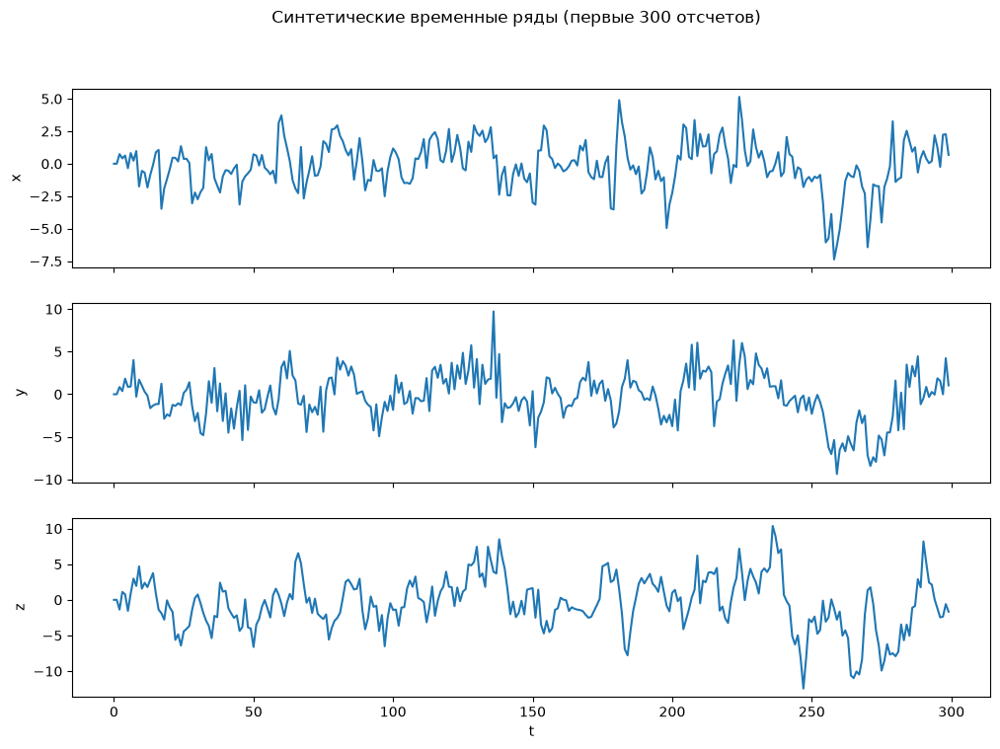

In [17]:
rng = np.random.default_rng(42)

T = 3000
sim_names = ["x", "y", "z"]

# Шум берем негауссовским (Лаплас), это допущение LiNGAM
X_sim = np.zeros((T, 3))
noise = rng.laplace(size=(T, 3))
for t in range(2, T):
    X_sim[t, 0] = 0.7 * X_sim[t - 1, 0] + noise[t, 0]
    X_sim[t, 1] = 0.9 * X_sim[t - 1, 0] + 0.5 * X_sim[t - 2, 1] + noise[t, 1]
    X_sim[t, 2] = 0.6 * X_sim[t - 1, 2] + 0.8 * X_sim[t - 2, 1] - 0.6 * X_sim[t - 2, 0] + noise[t, 2]

fig, axes = plt.subplots(3, 1, figsize=(12, 8), sharex=True)
for k in range(3):
    axes[k].plot(X_sim[:300, k])
    axes[k].set_ylabel(sim_names[k])
axes[-1].set_xlabel("t")
fig.suptitle("Синтетические временные ряды (первые 300 отсчетов)")
plt.show()

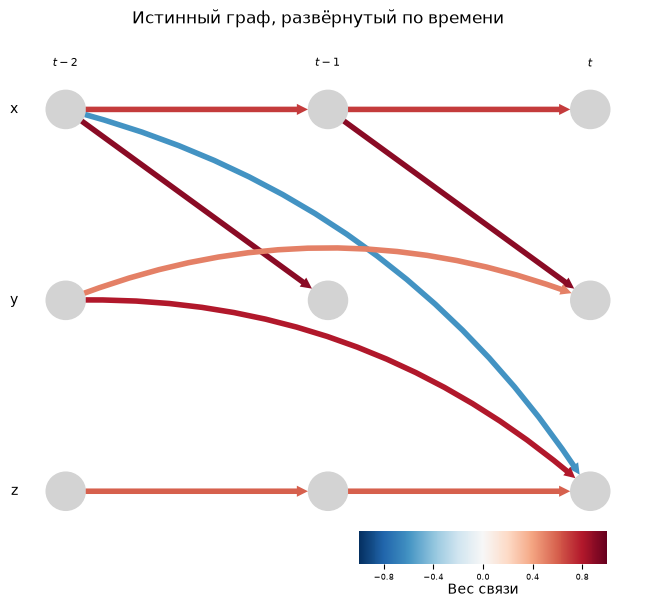

In [18]:
# A_lag[i, j] — влияние ряда i в момент t - lag на ряд j в момент t
A1_true = np.array([
    [0.7, 0.9, 0.0],
    [0.0, 0.0, 0.0],
    [0.0, 0.0, 0.6],
])
A2_true = np.array([
    [0.0, 0.0, -0.6],
    [0.0, 0.5, 0.8],
    [0.0, 0.0, 0.0],
])
true_matrices = [np.zeros((3, 3)), A1_true, A2_true]

graph_true, val_true = to_tigramite(true_matrices)

tp.plot_time_series_graph(
    graph=graph_true,
    val_matrix=val_true,
    var_names=sim_names,
    link_colorbar_label="Вес связи",
    figsize=(8, 6)
)
plt.suptitle("Истинный граф, развёрнутый по времени")
plt.show()

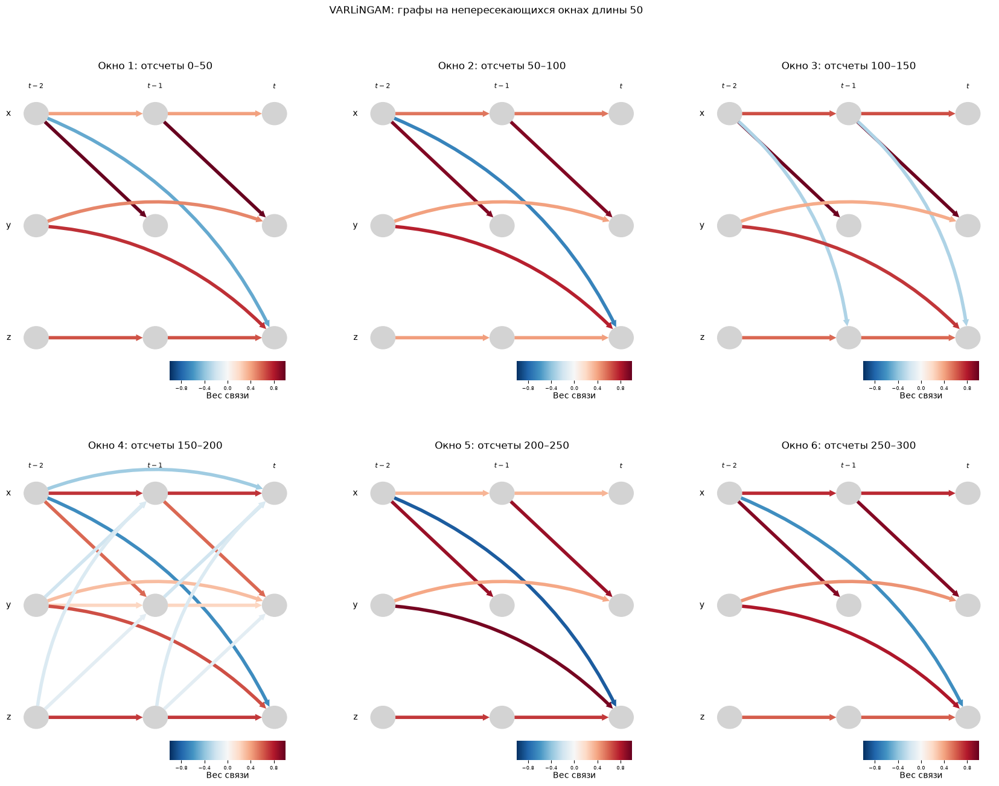

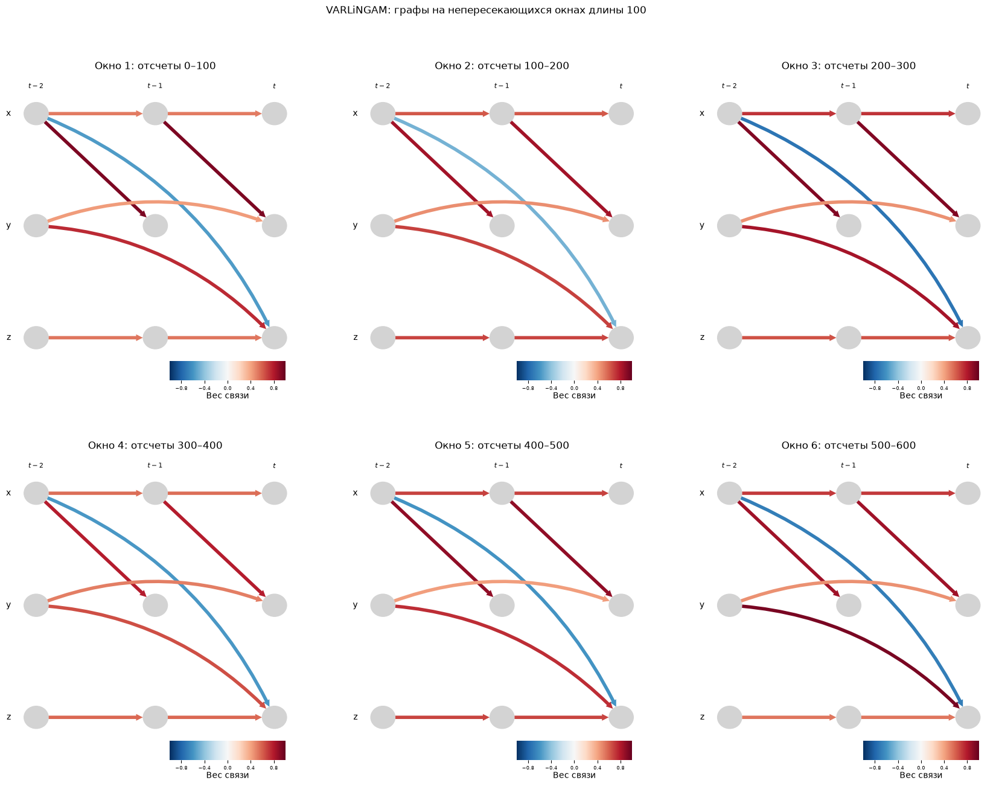

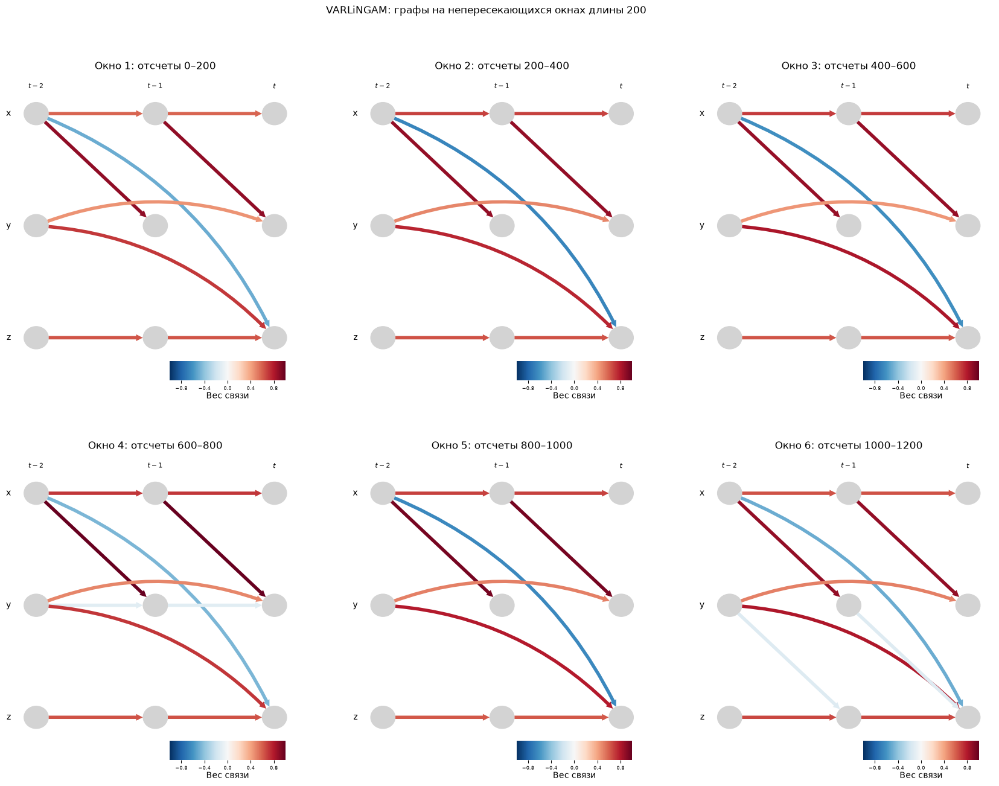

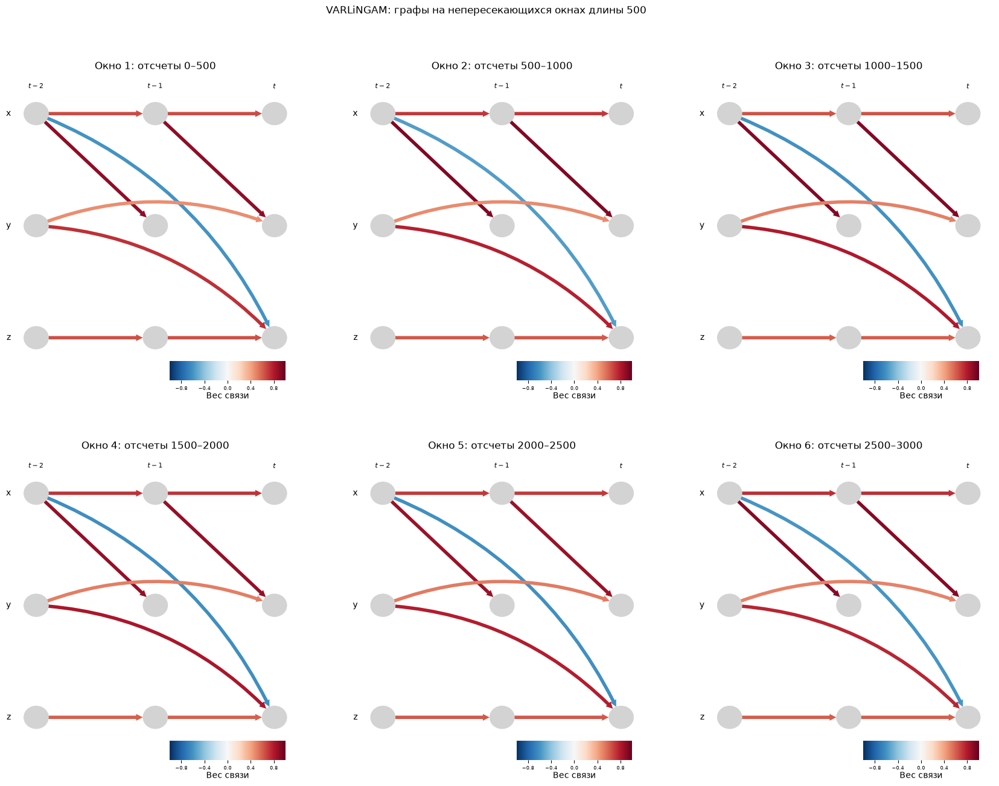

In [19]:
sim_sizes = [50, 100, 200, 500]

# 6 непересекающихся окон длины win, на каждом обучаем модель и рисуем граф
def plot_sim_windows(name, get_matrices, label, win):
    win_starts = list(range(0, 6 * win, win))
    fig, axes = plt.subplots(2, 3, figsize=(21, 14))
    axes = axes.reshape(-1)
    for k in range(len(win_starts)):
        s = win_starts[k]
        graph_k, val_k = to_tigramite(get_matrices(X_sim[s:s + win]))
        tp.plot_time_series_graph(
            graph=graph_k,
            val_matrix=val_k,
            var_names=sim_names,
            fig_ax=(fig, axes[k]),
            link_colorbar_label=label
        )
        axes[k].set_title(f"Окно {k + 1}: отсчеты {s}–{s + win}", pad=25)
    fig.subplots_adjust(hspace=0.4)
    fig.suptitle(f"{name}: графы на непересекающихся окнах длины {win}")
    plt.show()

for win in sim_sizes:
    plot_sim_windows("VARLiNGAM", matrices_varlingam, "Вес связи", win)

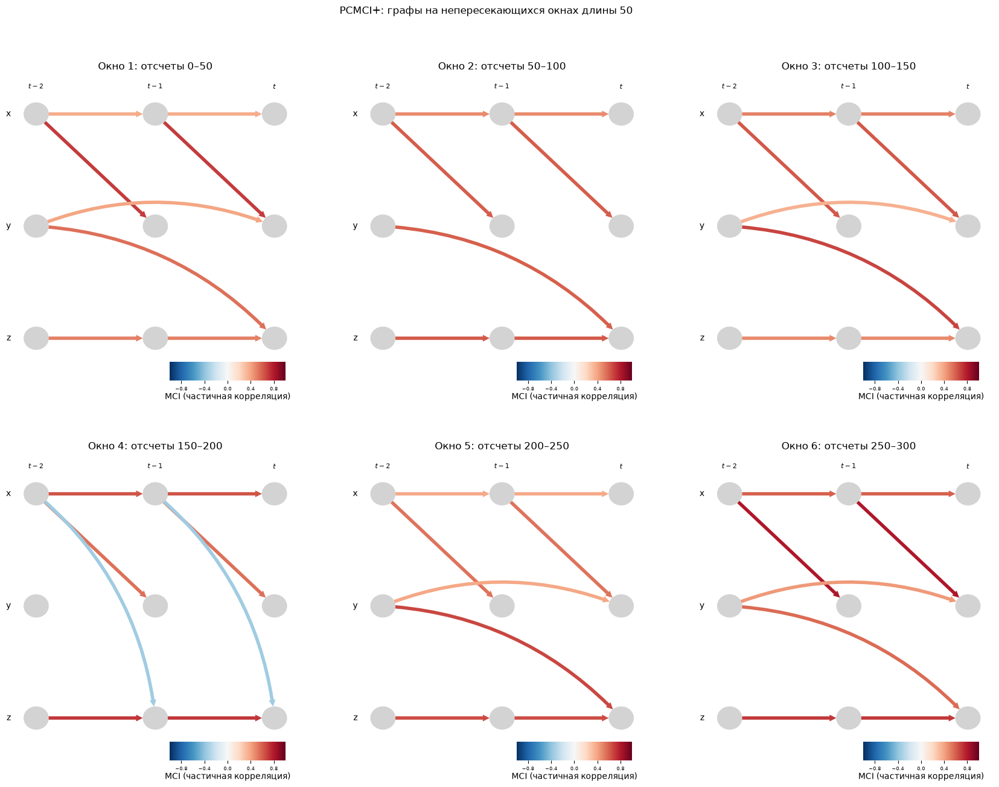

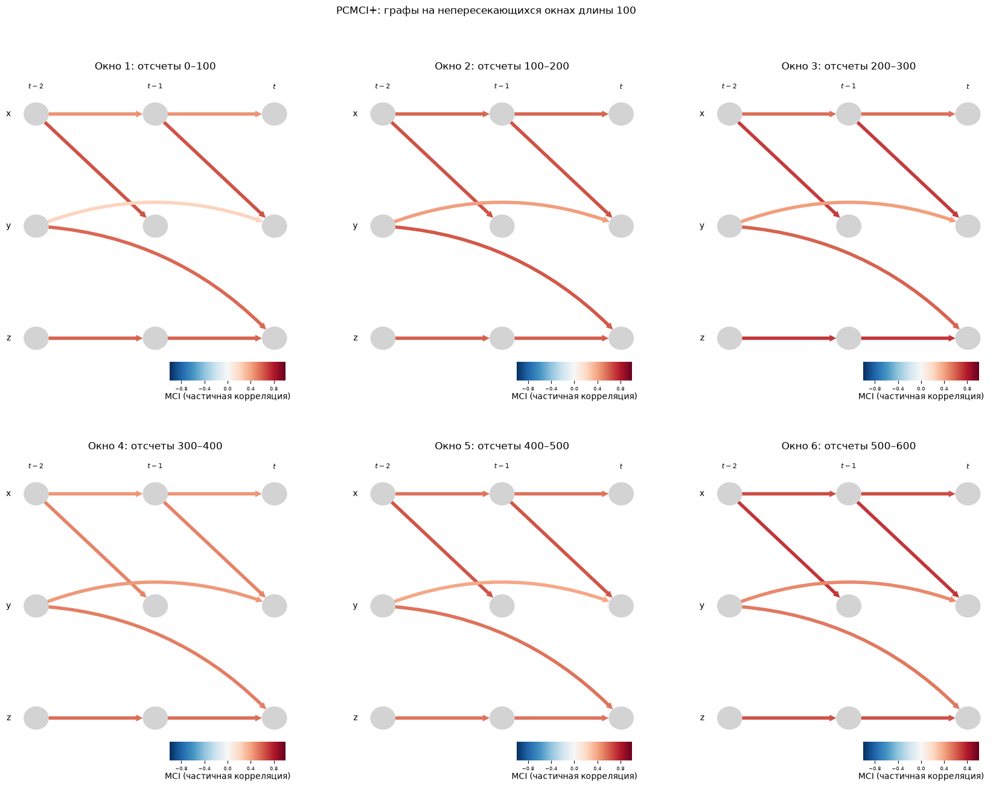

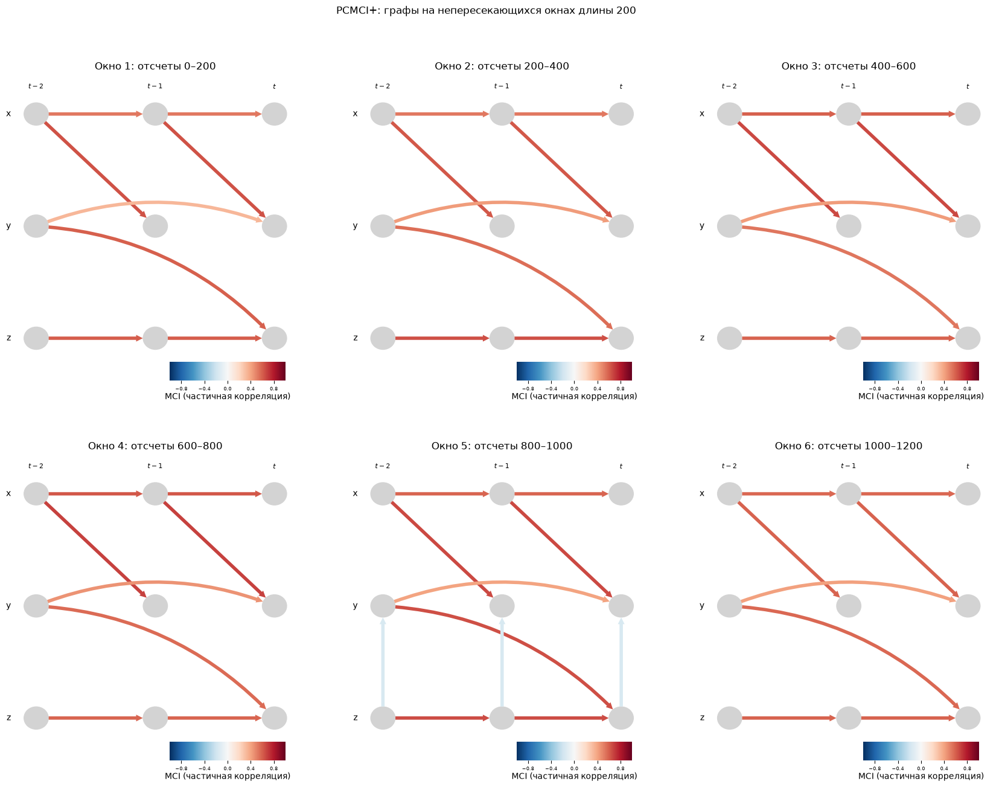

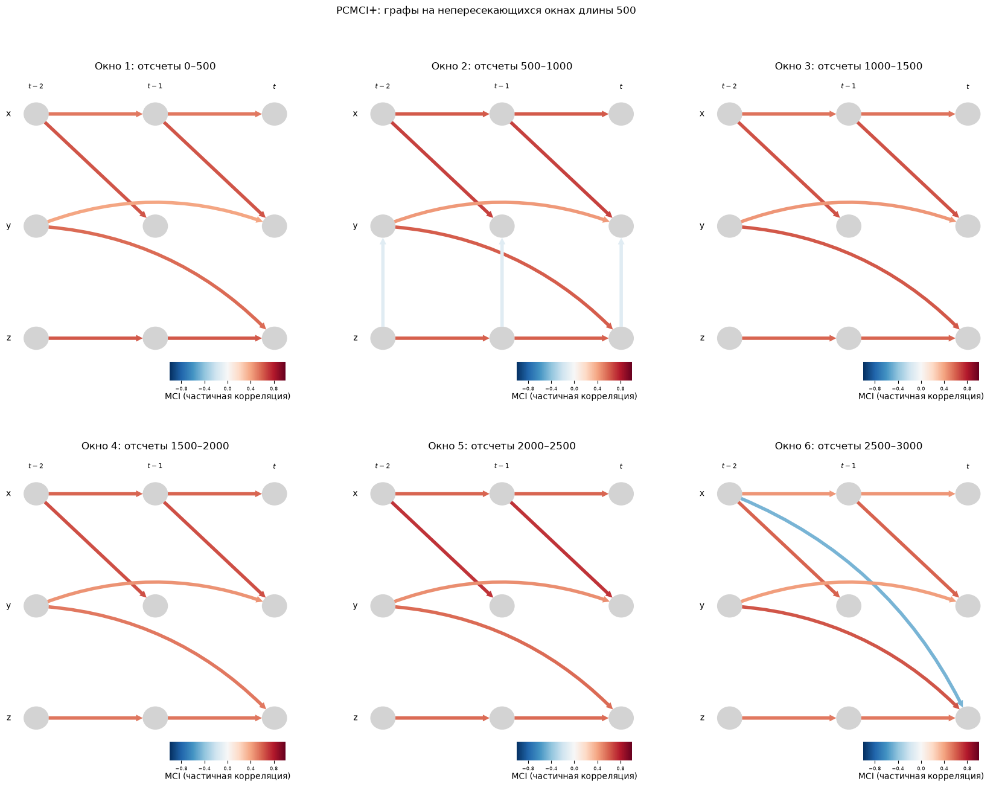

In [20]:
def sim_matrices_pcmci(X_part):
    data_part = pp.DataFrame(X_part.copy(), var_names=sim_names)
    model = PCMCI(dataframe=data_part, cond_ind_test=ParCorr(significance="analytic"), verbosity=0)
    results = model.run_pcmciplus(tau_min=0, tau_max=2, pc_alpha=0.05)
    M = np.where(results["graph"] == "-->", results["val_matrix"], 0)
    return [M[:, :, tau] for tau in range(M.shape[2])]

for win in sim_sizes:
    plot_sim_windows("PCMCI+", sim_matrices_pcmci, "MCI (частичная корреляция)", win)

Теперь NOTEARS для временных рядов — DYNOTEARS (Pamfil et al., 2020). Готовая реализация есть в `causalnex`, но она ставится только на Python < 3.11, поэтому напишем его сами по образцу `notears_linear`. Модель:

$$
X_t = X_t W + X_{t-1} A_1 + X_{t-2} A_2 + \varepsilon_t,
$$

где $W$ — связи на лаге 0, он обязан быть ациклическим (то же ограничение $h(W)=\operatorname{tr} e^{W\circ W}-d=0$, что в NOTEARS), а на матрицы лагов $A_\tau$ ограничений нет. Минимизируем $\frac{1}{2n}\|X_t - X_t W - [X_{t-1}, X_{t-2}]A\|^2 + \lambda_W\|W\|_1 + \lambda_A\|A\|_1$ при $h(W)=0$ методом расширенного Лагранжиана, как в `notears_linear`.

In [6]:
import scipy.linalg as slin
import scipy.optimize as sopt

def dynotears(X, lags, lambda_w, lambda_a, w_threshold, max_iter=100, h_tol=1e-8, rho_max=1e+16):
    n, d = X.shape
    X = X - X.mean(axis=0)
    X_now = X[lags:]
    # Y = [X_{t-1}, ..., X_{t-lags}]
    Y = np.hstack([X[lags - tau:n - tau] for tau in range(1, lags + 1)])
    m = X_now.shape[0]
    k = d * d + lags * d * d

    # Как в notears_linear, веса раскладываем на положительную и отрицательную части: w = [w_pos, w_neg]
    def _adj(w):
        v = w[:k] - w[k:]
        return v[:d * d].reshape(d, d), v[d * d:].reshape(lags * d, d)

    def _h(W):
        E = slin.expm(W * W)
        return np.trace(E) - d, E.T * W * 2

    penalty = np.concatenate([np.full(d * d, lambda_w), np.full(lags * d * d, lambda_a)] * 2)

    def _func(w):
        W, A = _adj(w)
        R = X_now - X_now @ W - Y @ A
        loss = 0.5 / m * (R ** 2).sum()
        h, G_h = _h(W)
        obj = loss + 0.5 * rho * h * h + alpha * h + penalty @ w
        G_W = -1.0 / m * X_now.T @ R + (rho * h + alpha) * G_h
        G_A = -1.0 / m * Y.T @ R
        G = np.concatenate([G_W.ravel(), G_A.ravel()])
        return obj, np.concatenate([G, -G]) + penalty

    # Петли на лаге 0 запрещены, на лагах 1..lags разрешены
    bnds_half = [(0, 0) if i == j else (0, None) for i in range(d) for j in range(d)] + [(0, None)] * (lags * d * d)
    bnds = bnds_half * 2
    w_est, rho, alpha, h = np.zeros(2 * k), 1.0, 0.0, np.inf
    for _ in range(max_iter):
        w_new, h_new = None, None
        while rho < rho_max:
            sol = sopt.minimize(_func, w_est, method="L-BFGS-B", jac=True, bounds=bnds)
            w_new = sol.x
            h_new, _ = _h(_adj(w_new)[0])
            if h_new > 0.25 * h:
                rho *= 10
            else:
                break
        w_est, h = w_new, h_new
        alpha += rho * h
        if h <= h_tol or rho >= rho_max:
            break
    W, A = _adj(w_est)
    # Тот же формат, что у остальных моделей: matrices[tau][i, j] — влияние ряда i в момент t - tau на ряд j в момент t
    matrices = [W] + [A[tau * d:(tau + 1) * d] for tau in range(lags)]
    for M in matrices:
        M[np.abs(M) < w_threshold] = 0
    return matrices

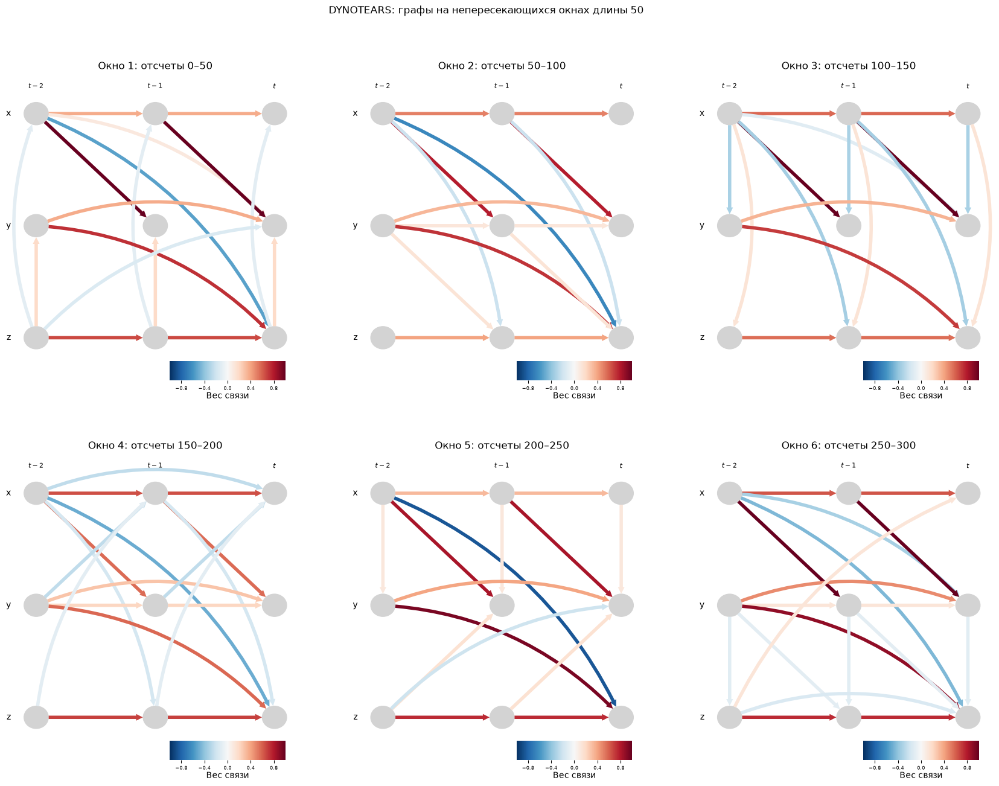

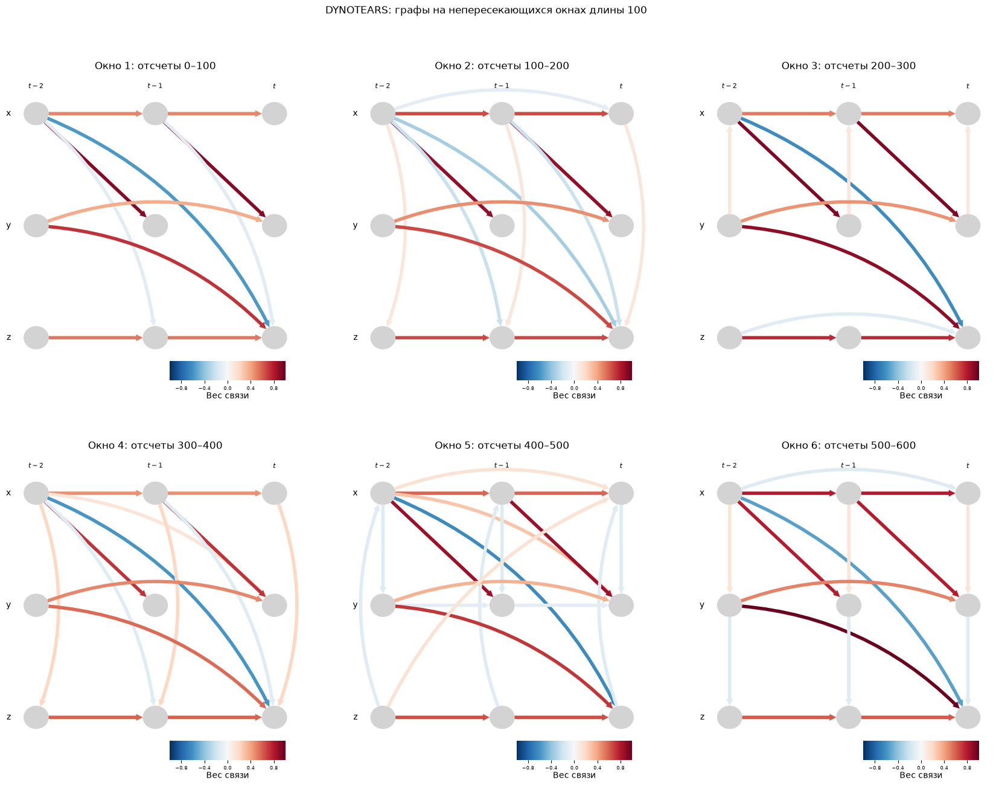

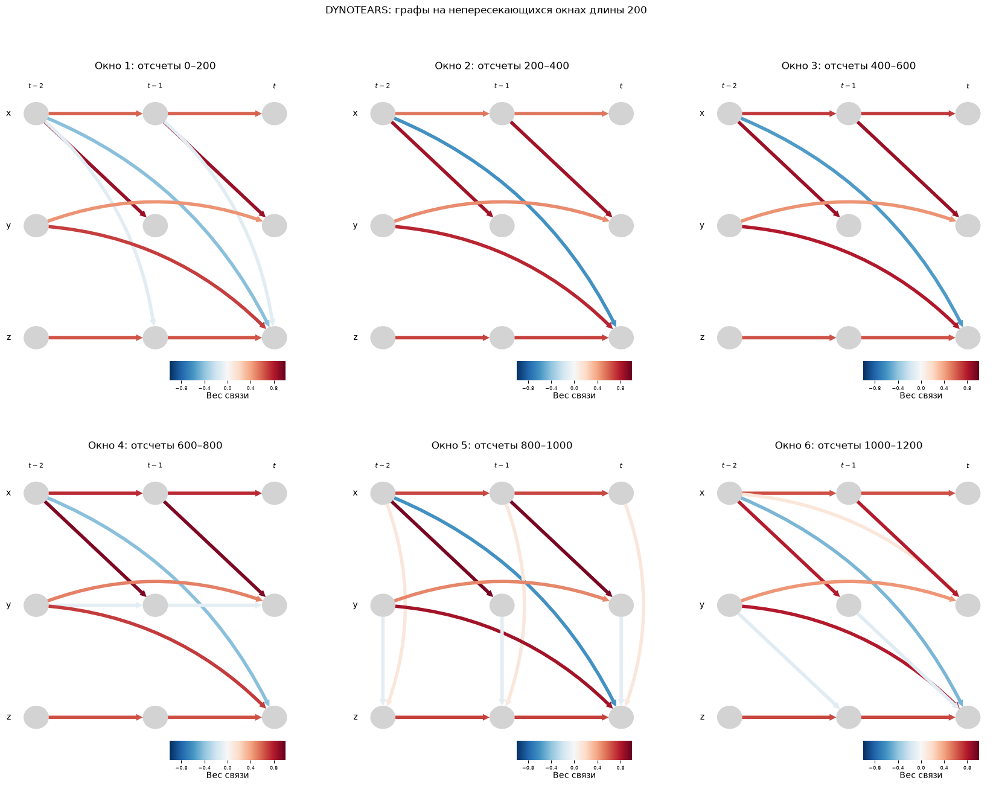

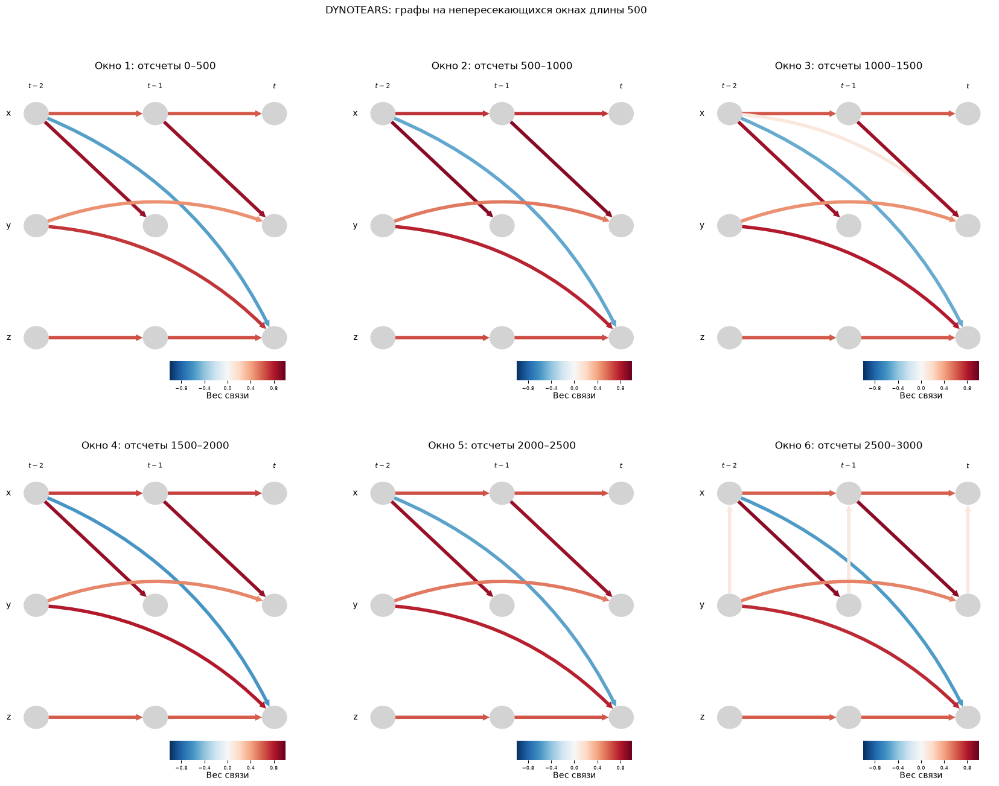

In [7]:
def sim_matrices_dynotears(X_part):
    return dynotears(X_part, lags=2, lambda_w=0.05, lambda_a=0.05, w_threshold=threshold)

for win in sim_sizes:
    plot_sim_windows("DYNOTEARS", sim_matrices_dynotears, "Вес связи", win)

In [8]:
import pandas as pd

# Ребро — тройка (откуда, куда, лаг). Петли на лаге 0 не учитываем
def sim_edges(matrices):
    edges = set()
    for tau in range(len(matrices)):
        for i, j in np.argwhere(np.abs(matrices[tau]) >= threshold):
            if tau > 0 or i != j:
                edges.add((sim_names[i], sim_names[j], tau))
    return edges

true_edges = sim_edges(true_matrices)

sim_models = {"VARLiNGAM": matrices_varlingam, "PCMCI+": sim_matrices_pcmci, "DYNOTEARS": sim_matrices_dynotears}

# Числа — сумма по 6 окнам, всего истинных связей 6 * 6 = 36
rows = []
for win in sim_sizes:
    for name in sim_models:
        correct = missed = extra = 0
        for s in range(0, 6 * win, win):
            found = sim_edges(sim_models[name](X_sim[s:s + win]))
            correct += len(found & true_edges)
            missed += len(true_edges - found)
            extra += len(found - true_edges)
        rows.append({"Размер окна": win, "Метод": name, "Правильные": correct, "Пропущенные": missed, "Ложные": extra})

pd.DataFrame(rows)

,Размер окна,Метод,Правильные,Пропущенные,Ложные
0,50,VARLiNGAM,35,1,6
1,50,PCMCI+,27,9,1
2,50,DYNOTEARS,35,1,25
3,100,VARLiNGAM,36,0,0
4,100,PCMCI+,30,6,0
5,100,DYNOTEARS,36,0,18
6,200,VARLiNGAM,36,0,2
7,200,PCMCI+,30,6,1
8,200,DYNOTEARS,36,0,6
9,500,VARLiNGAM,36,0,0


Теперь возьмем реальные данные Gas Furnace (Box, Jenkins, Reinsel, 1994): $X_t$ — скорость подачи газа, $Y_t$ — концентрация CO2 на выходе печи. Априорный граф зададим по модели VAR(2) их статьи https://www.itl.nist.gov/div898/handbook/pmc/section4/pmc451.htm? :

$$
\begin{aligned}
X_t={}&1.683X_{t-1}-0.860X_{t-2}\\
&-0.076Y_{t-1}+0.045Y_{t-2}+\varepsilon_t^X,\\[2mm]
Y_t={}&1.226Y_{t-1}-0.409Y_{t-2}\\
&+0.229X_{t-1}-0.805X_{t-2}+\varepsilon_t^Y.
\end{aligned}
$$

In [22]:
# Файл скачан с https://www.itl.nist.gov/div898/handbook/datasets/GAS_FURNACE.DAT и лежит рядом с ноутбуком
gas = pd.read_csv("GAS_FURNACE.DAT", sep=r"\s+")
X_gas = gas.values
gas_names = ["X", "Y"]

print("Размер:", X_gas.shape)
gas.head()

Размер: (296, 2)


,GasRate(ft3/min),%C02
0,-0.109,53.8
1,0.000,53.6
2,0.178,53.5
3,0.339,53.5
4,0.373,53.4


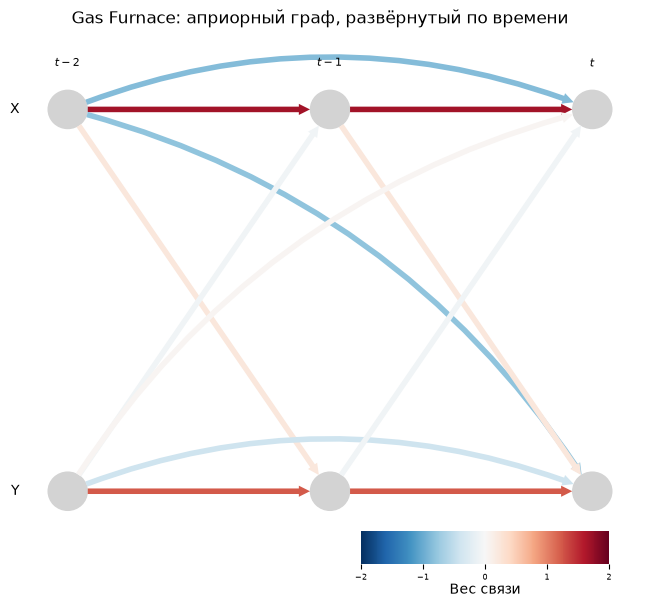

In [23]:
# В формуле есть слабые связи Y -> X (0.076 и 0.045), поэтому порог берем меньше, чем 0.1
gas_threshold = 0.01

# A_lag[i, j] — влияние ряда i в момент t - lag на ряд j в момент t
A1_gas = np.array([
    [1.683, 0.229],
    [-0.076, 1.226],
])
A2_gas = np.array([
    [-0.860, -0.805],
    [0.045, -0.409],
])
gas_prior = [np.zeros((2, 2)), A1_gas, A2_gas]

graph_prior, val_prior = to_tigramite(gas_prior, gas_threshold)

# Веса тут бывают больше 1, поэтому шкала цвета от -2 до 2
tp.plot_time_series_graph(
    graph=graph_prior,
    val_matrix=val_prior,
    var_names=gas_names,
    link_colorbar_label="Вес связи",
    vmin_edges=-2,
    vmax_edges=2,
    edge_ticks=1,
    figsize=(8, 6)
)
plt.suptitle("Gas Furnace: априорный граф, развёрнутый по времени")
plt.show()

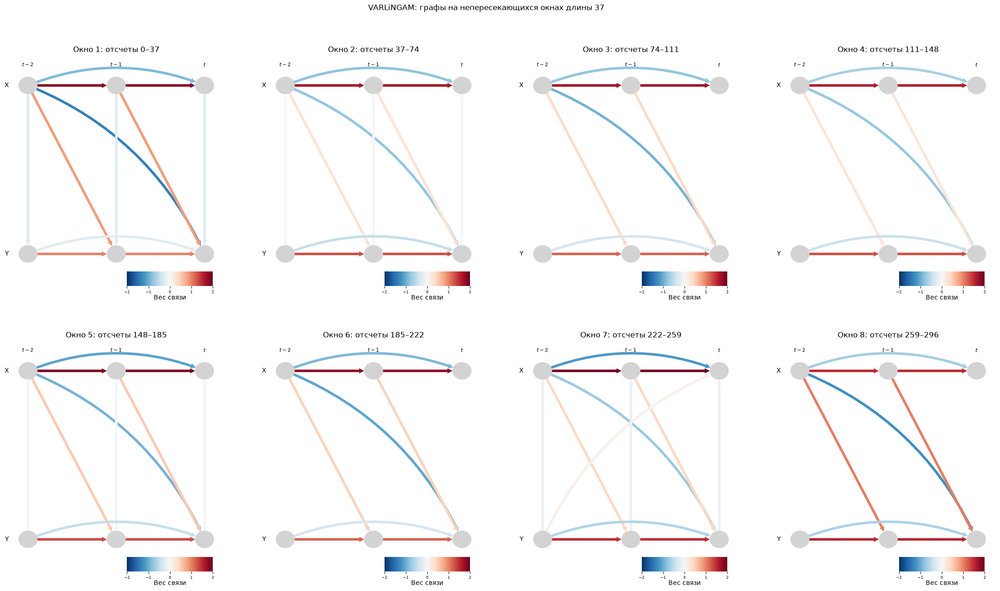

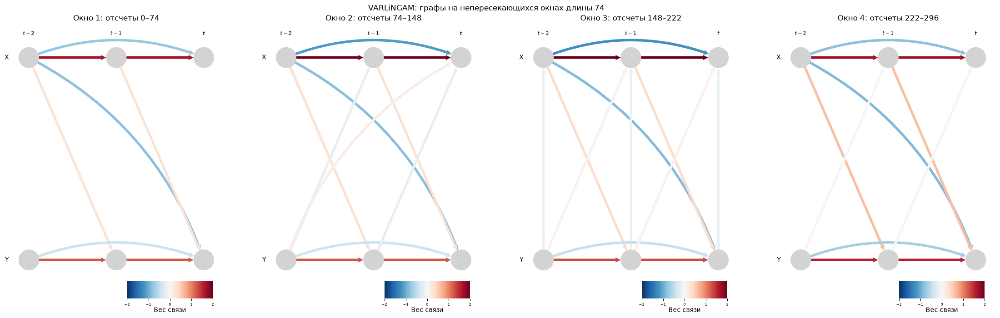

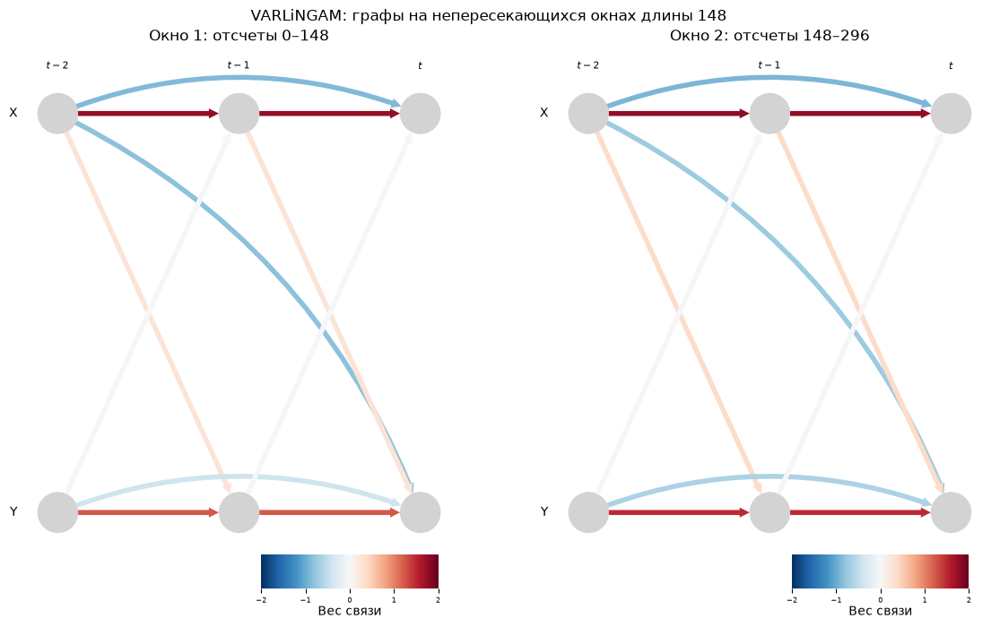

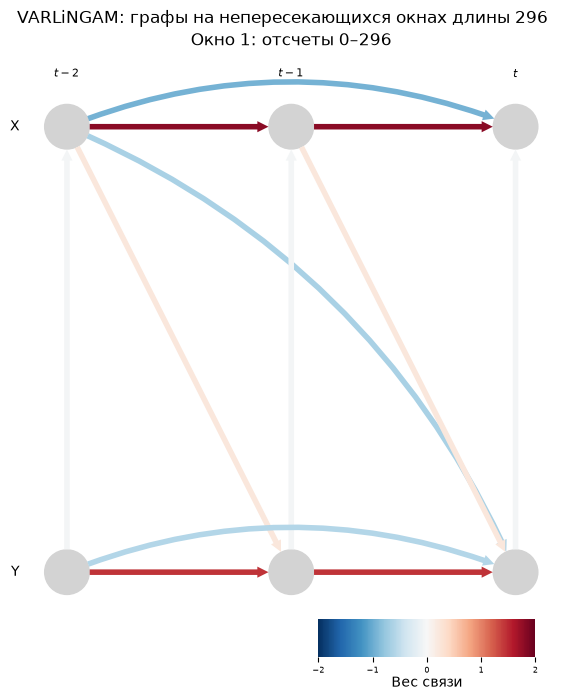

In [24]:
# 296 = 8 * 37, то есть ряд целиком делится на 8, 4, 2 и 1 окно
gas_sizes = [37, 74, 148, 296]

# Непересекающиеся окна длины win, на каждом обучаем модель и рисуем граф
def plot_gas_windows(name, get_matrices, label, vmax, win):
    gas_starts = list(range(0, len(X_gas) - win + 1, win))
    n_cols = min(len(gas_starts), 4)
    n_rows = int(np.ceil(len(gas_starts) / n_cols))
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(7 * n_cols, 7 * n_rows))
    axes = np.array(axes).reshape(-1)
    for k in range(len(gas_starts)):
        s = gas_starts[k]
        graph_k, val_k = to_tigramite(get_matrices(X_gas[s:s + win]), gas_threshold)
        tp.plot_time_series_graph(
            graph=graph_k,
            val_matrix=val_k,
            var_names=gas_names,
            fig_ax=(fig, axes[k]),
            link_colorbar_label=label,
            vmin_edges=-vmax,
            vmax_edges=vmax,
            edge_ticks=vmax / 2
        )
        axes[k].set_title(f"Окно {k + 1}: отсчеты {s}–{s + win}", pad=25)
    fig.subplots_adjust(hspace=0.4)
    fig.suptitle(f"{name}: графы на непересекающихся окнах длины {win}")
    plt.show()

for win in gas_sizes:
    plot_gas_windows("VARLiNGAM", matrices_varlingam, "Вес связи", 2, win)

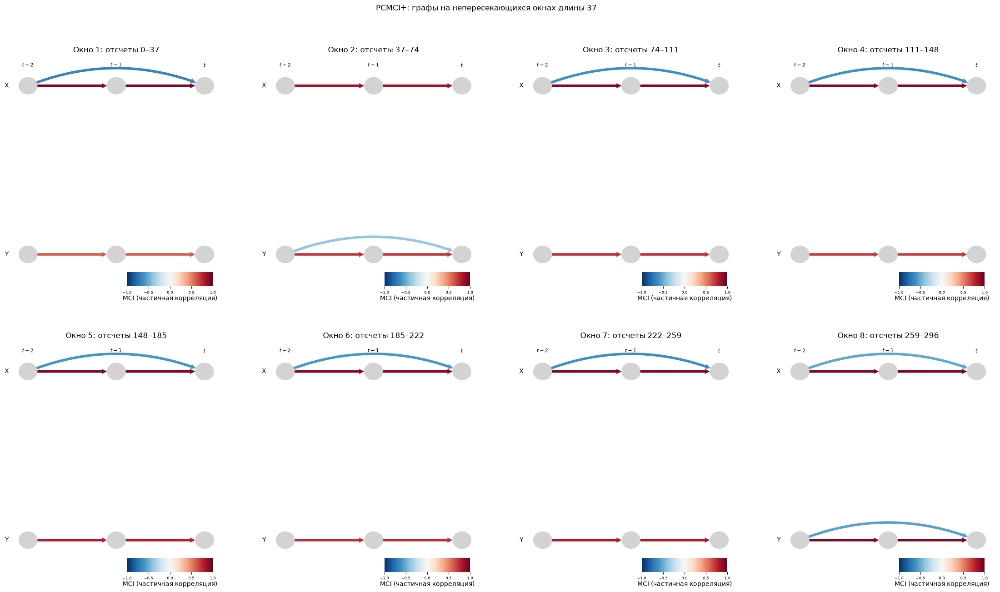

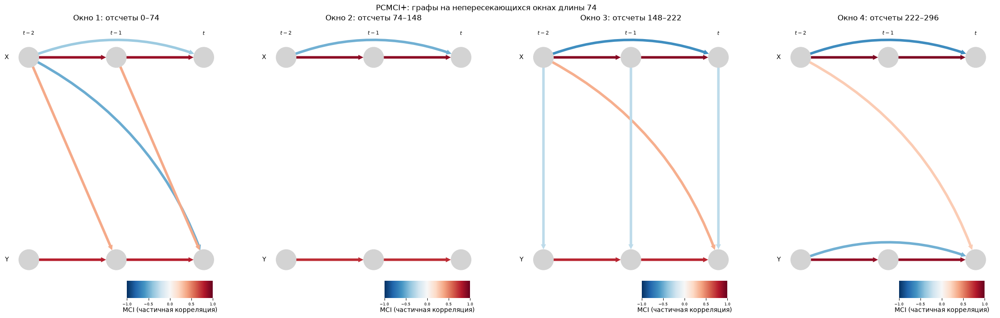

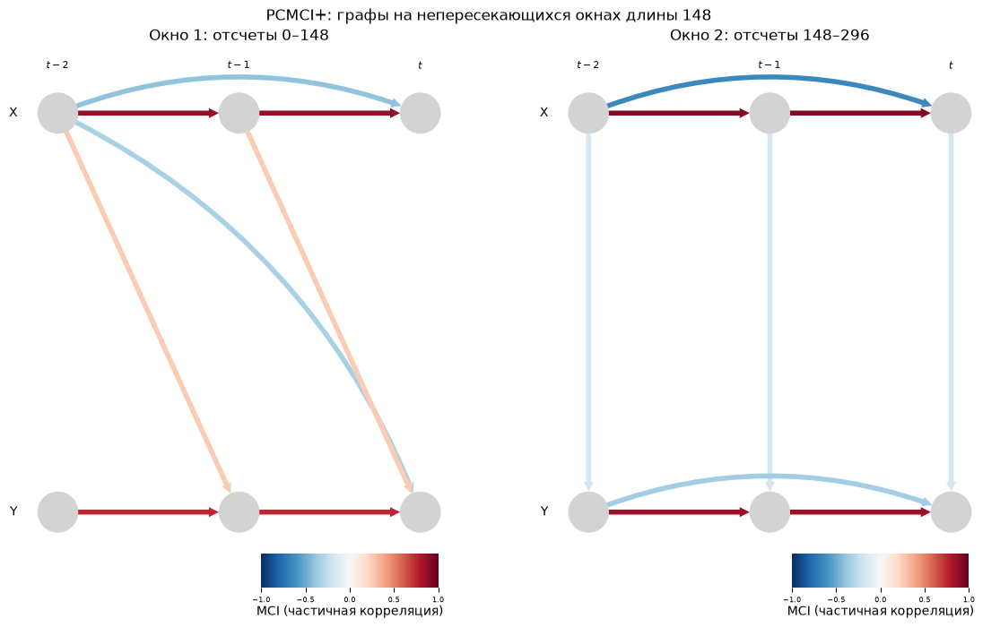

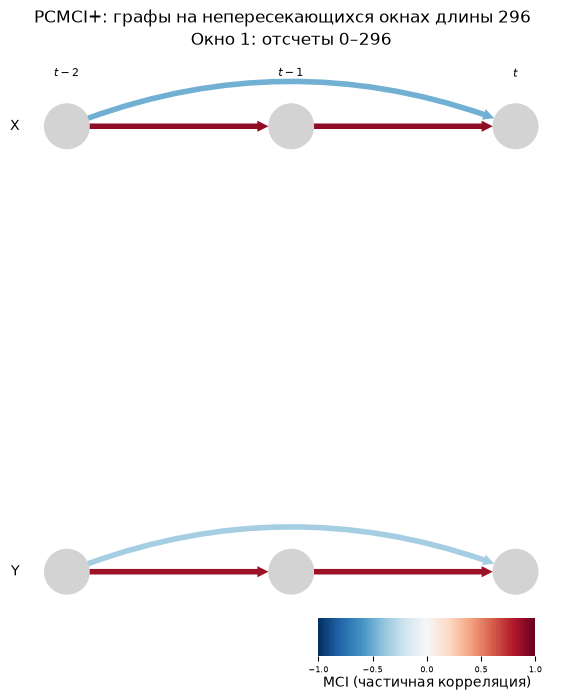

In [25]:
def gas_matrices_pcmci(X_part):
    data_part = pp.DataFrame(X_part.copy(), var_names=gas_names)
    model = PCMCI(dataframe=data_part, cond_ind_test=ParCorr(significance="analytic"), verbosity=0)
    results = model.run_pcmciplus(tau_min=0, tau_max=2, pc_alpha=0.05)
    M = np.where(results["graph"] == "-->", results["val_matrix"], 0)
    return [M[:, :, tau] for tau in range(M.shape[2])]

for win in gas_sizes:
    plot_gas_windows("PCMCI+", gas_matrices_pcmci, "MCI (частичная корреляция)", 1, win)

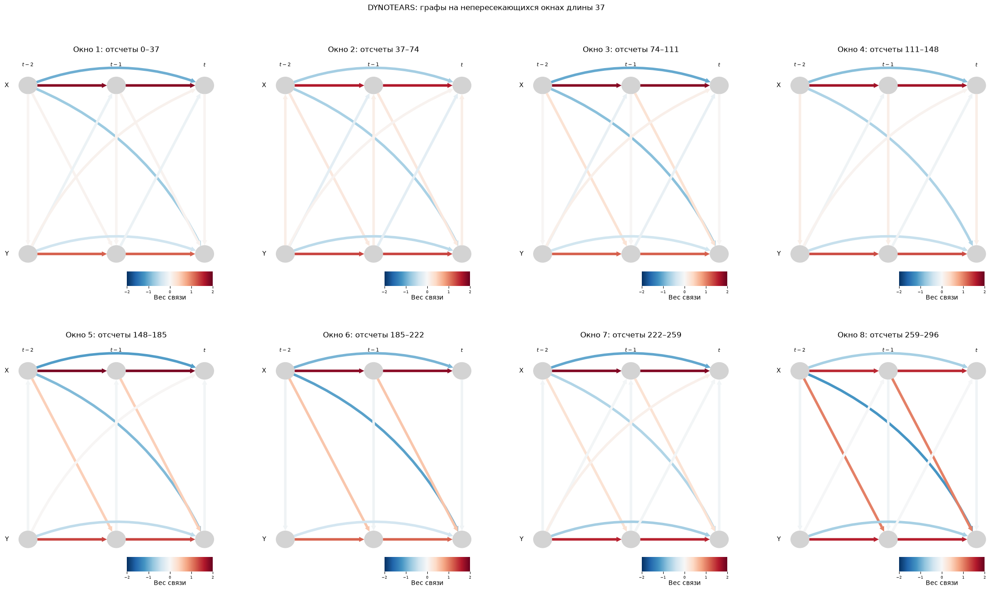

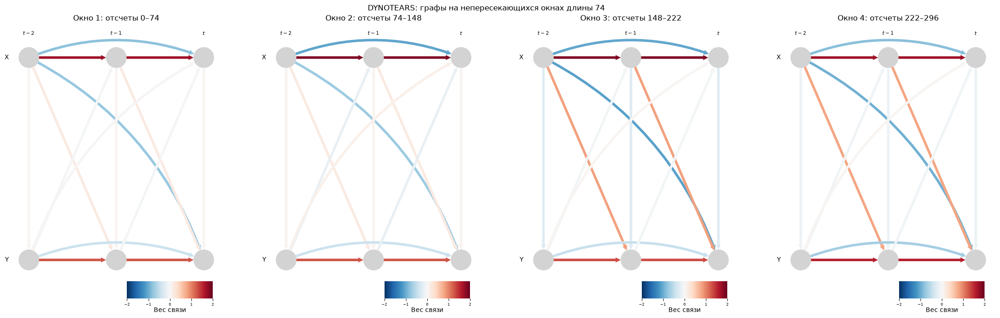

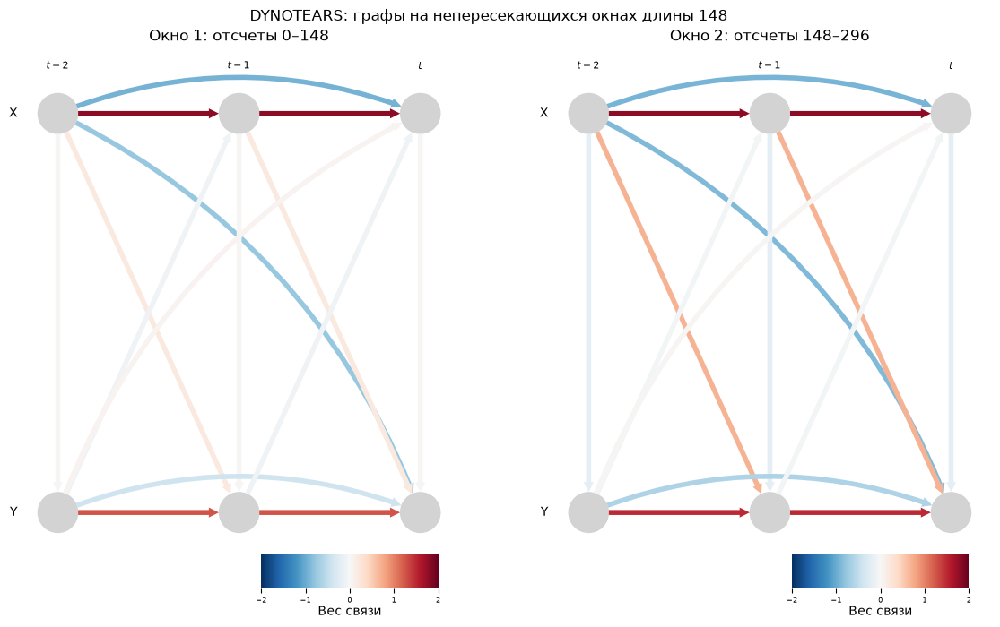

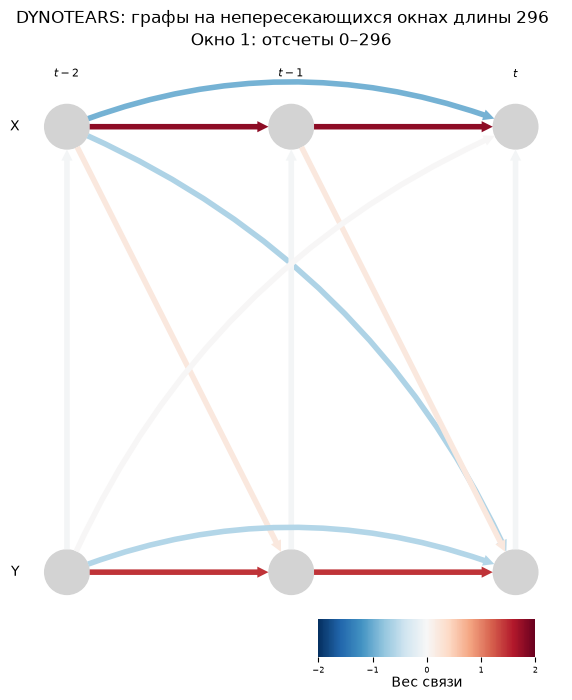

In [27]:
# Данные печи не стандартизуем, чтобы веса были в тех же единицах, что в априорной модели и у VARLiNGAM.
# Штраф L1 берем маленьким: уже при 0.01 пропадают слабые связи Y -> X и даже X -> Y на лаге 1
def gas_matrices_dynotears(X_part):
    return dynotears(X_part, lags=2, lambda_w=0.001, lambda_a=0.001, w_threshold=gas_threshold)

for win in gas_sizes:
    plot_gas_windows("DYNOTEARS", gas_matrices_dynotears, "Вес связи", 2, win)

In [28]:
# Ребро — тройка (откуда, куда, лаг). Петли на лаге 0 не учитываем
def gas_edges(matrices):
    edges = set()
    for tau in range(len(matrices)):
        for i, j in np.argwhere(np.abs(matrices[tau]) >= gas_threshold):
            if tau > 0 or i != j:
                edges.add((gas_names[i], gas_names[j], tau))
    return edges

prior_edges = gas_edges(gas_prior)

# Всего возможных ребер в одном окне: лаги 0, 1, 2 без петель на лаге 0
n_possible = 3 * len(gas_names) ** 2 - len(gas_names)

gas_models = {"VARLiNGAM": matrices_varlingam, "PCMCI+": gas_matrices_pcmci, "DYNOTEARS": gas_matrices_dynotears}

# Числа — сумма по окнам, в априорном графе 8 связей, то есть всего 8 * (число окон)
# Precision, Recall, F1 и Accuracy считаем по этим суммам
rows = []
for win in gas_sizes:
    gas_starts = list(range(0, len(X_gas) - win + 1, win))
    for name in gas_models:
        correct = missed = extra = 0
        for s in gas_starts:
            found = gas_edges(gas_models[name](X_gas[s:s + win]))
            correct += len(found & prior_edges)
            missed += len(prior_edges - found)
            extra += len(found - prior_edges)
        # Правильно не найденные ребра — те, которых нет ни в априорном графе, ни в найденном
        correct_absent = n_possible * len(gas_starts) - correct - missed - extra
        precision = correct / (correct + extra) if correct + extra > 0 else 0.0
        recall = correct / (correct + missed)
        f1 = 2 * precision * recall / (precision + recall) if precision + recall > 0 else 0.0
        accuracy = (correct + correct_absent) / (n_possible * len(gas_starts))
        rows.append({"Размер окна": win, "Окон": len(gas_starts), "Метод": name, "Правильные": correct, "Пропущенные": missed, "Ложные": extra,
                     "Precision": round(precision, 2), "Recall": round(recall, 2), "F1": round(f1, 2), "Accuracy": round(accuracy, 2)})

pd.DataFrame(rows)

,Размер окна,Окон,Метод,Правильные,Пропущенные,Ложные,Precision,Recall,F1,Accuracy
0,37,8,VARLiNGAM,49,15,4,0.92,0.77,0.84,0.76
1,37,8,PCMCI+,25,39,0,1.00,0.39,0.56,0.51
2,37,8,DYNOTEARS,59,5,8,0.88,0.92,0.90,0.84
3,74,4,VARLiNGAM,28,4,1,0.97,0.88,0.92,0.88
4,74,4,PCMCI+,17,15,1,0.94,0.53,0.68,0.60
5,74,4,DYNOTEARS,32,0,4,0.89,1.00,0.94,0.90
6,148,2,VARLiNGAM,14,2,0,1.00,0.88,0.93,0.90
7,148,2,PCMCI+,9,7,1,0.90,0.56,0.69,0.60
8,148,2,DYNOTEARS,16,0,2,0.89,1.00,0.94,0.90
9,296,1,VARLiNGAM,6,2,1,0.86,0.75,0.80,0.70


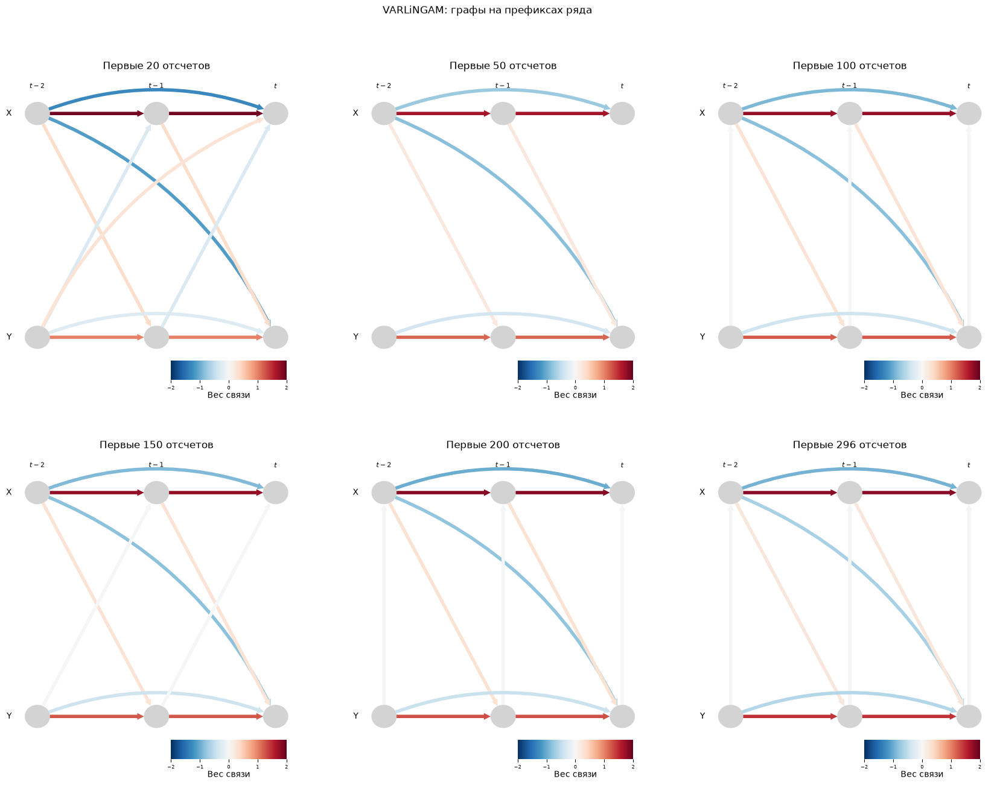

VARLiNGAM: число ребер = [8, 6, 7, 7, 7, 7]
VARLiNGAM: совпадают с предыдущим префиксом = [6, 6, 6, 6, 7]
VARLiNGAM: Жаккар соседних префиксов = [0.75 0.86 0.75 0.75 1.  ]


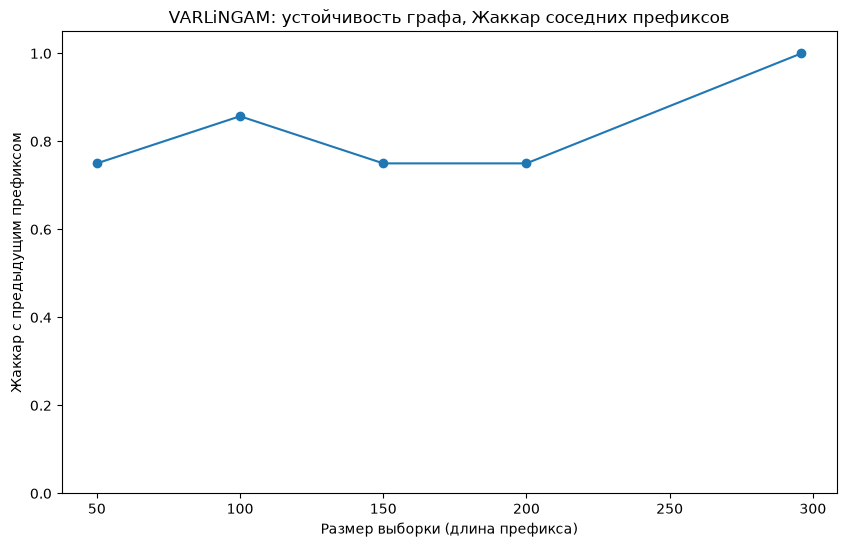

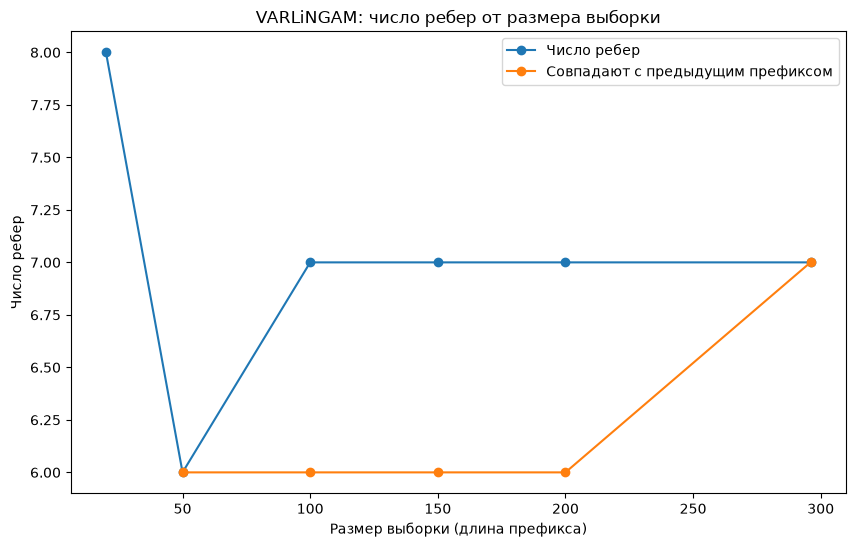

In [29]:
# В ряде всего 296 отсчетов
gas_prefixes = [20, 50, 100, 150, 200, len(X_gas)]

# Обучаем модель на первых n отсчетах, рисуем графы и смотрим, как граф меняется при добавлении данных
def gas_prefix_analysis(name, get_matrices, label, vmax):
    prefix_matrices = [get_matrices(X_gas[:n]) for n in gas_prefixes]
    prefix_edges = [gas_edges(M) for M in prefix_matrices]

    fig, axes = plt.subplots(2, 3, figsize=(21, 14))
    axes = axes.reshape(-1)
    for k in range(len(gas_prefixes)):
        graph_k, val_k = to_tigramite(prefix_matrices[k], gas_threshold)
        tp.plot_time_series_graph(
            graph=graph_k,
            val_matrix=val_k,
            var_names=gas_names,
            fig_ax=(fig, axes[k]),
            link_colorbar_label=label,
            vmin_edges=-vmax,
            vmax_edges=vmax,
            edge_ticks=vmax / 2
        )
        axes[k].set_title(f"Первые {gas_prefixes[k]} отсчетов", pad=25)
    fig.subplots_adjust(hspace=0.4)
    fig.suptitle(f"{name}: графы на префиксах ряда")
    plt.show()

    jaccards = [jaccard(prefix_edges[k], prefix_edges[k + 1]) for k in range(len(gas_prefixes) - 1)]
    common = [len(prefix_edges[k] & prefix_edges[k + 1]) for k in range(len(gas_prefixes) - 1)]
    print(f"{name}: число ребер = {[len(e) for e in prefix_edges]}")
    print(f"{name}: совпадают с предыдущим префиксом = {common}")
    print(f"{name}: Жаккар соседних префиксов = {np.round(jaccards, 2)}")

    plt.figure(figsize=(10, 6))
    plt.plot(gas_prefixes[1:], jaccards, marker="o")
    plt.ylim(0, 1.05)
    plt.xlabel("Размер выборки (длина префикса)")
    plt.ylabel("Жаккар с предыдущим префиксом")
    plt.title(f"{name}: устойчивость графа, Жаккар соседних префиксов")
    plt.show()

    plt.figure(figsize=(10, 6))
    plt.plot(gas_prefixes, [len(e) for e in prefix_edges], marker="o", label="Число ребер")
    plt.plot(gas_prefixes[1:], common, marker="o", label="Совпадают с предыдущим префиксом")
    plt.xlabel("Размер выборки (длина префикса)")
    plt.ylabel("Число ребер")
    plt.title(f"{name}: число ребер от размера выборки")
    plt.legend()
    plt.show()

gas_prefix_analysis("VARLiNGAM", matrices_varlingam, "Вес связи", 2)

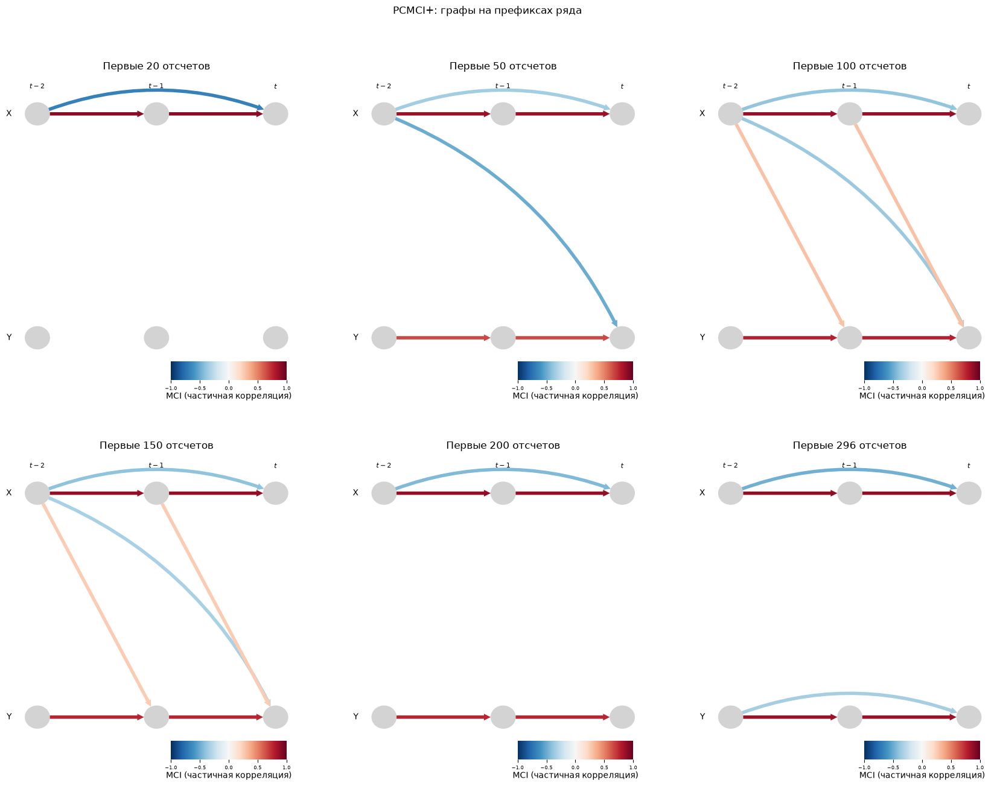

PCMCI+: число ребер = [2, 4, 5, 5, 3, 4]
PCMCI+: совпадают с предыдущим префиксом = [2, 4, 5, 3, 3]
PCMCI+: Жаккар соседних префиксов = [0.5  0.8  1.   0.6  0.75]


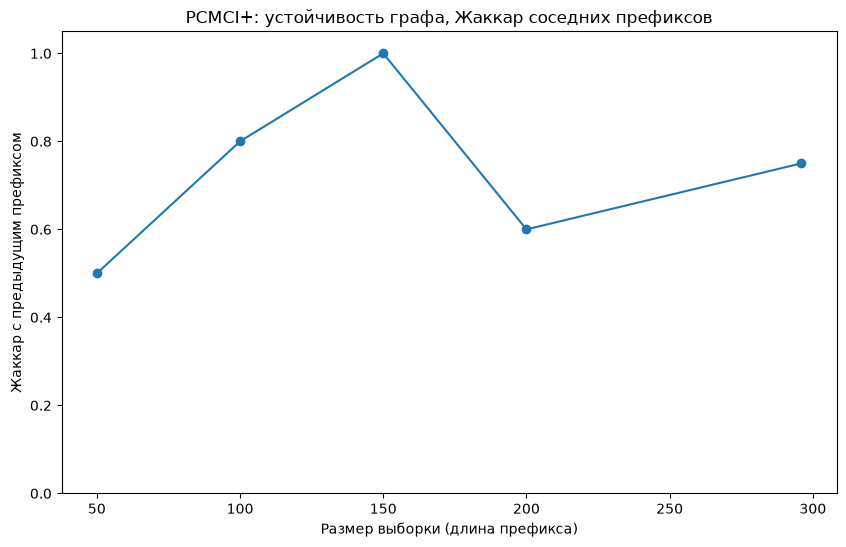

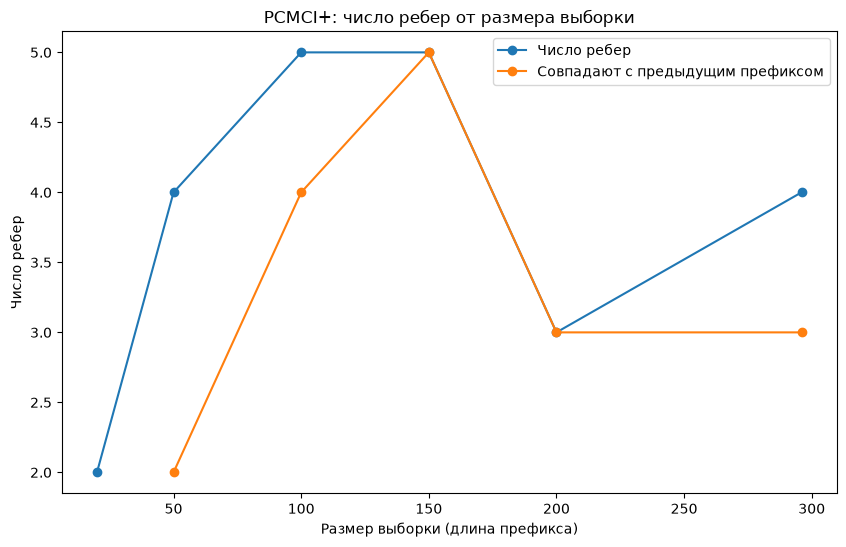

In [30]:
gas_prefix_analysis("PCMCI+", gas_matrices_pcmci, "MCI (частичная корреляция)", 1)

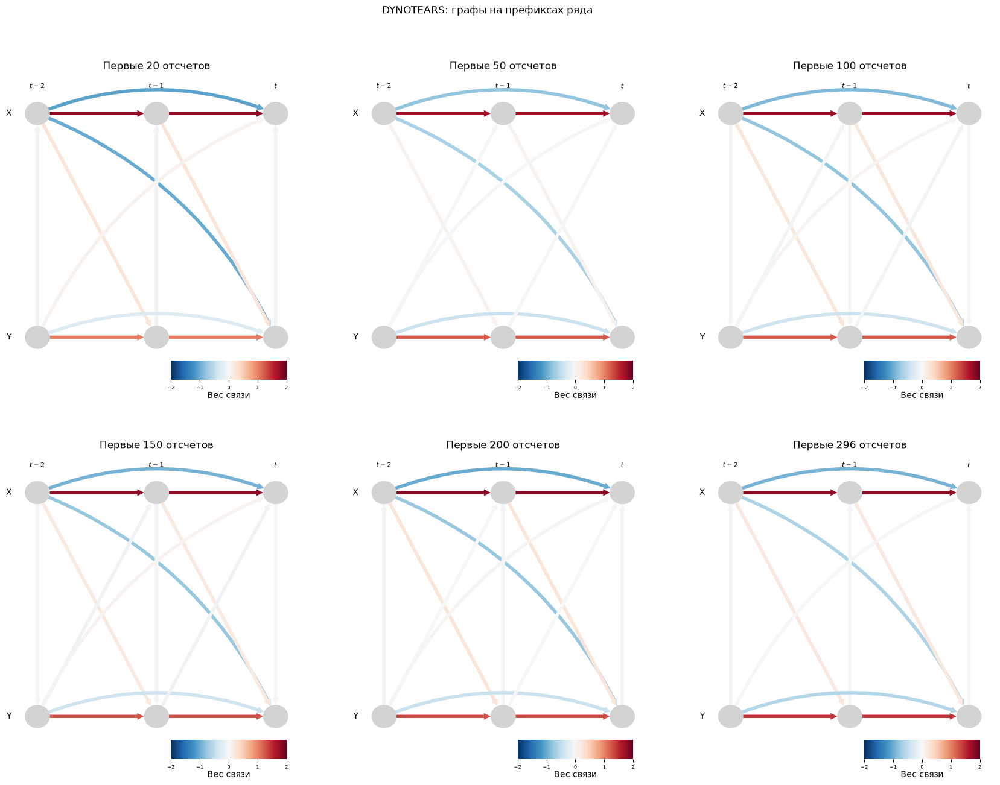

DYNOTEARS: число ребер = [8, 8, 9, 9, 9, 8]
DYNOTEARS: совпадают с предыдущим префиксом = [7, 8, 9, 8, 8]
DYNOTEARS: Жаккар соседних префиксов = [0.78 0.89 1.   0.8  0.89]


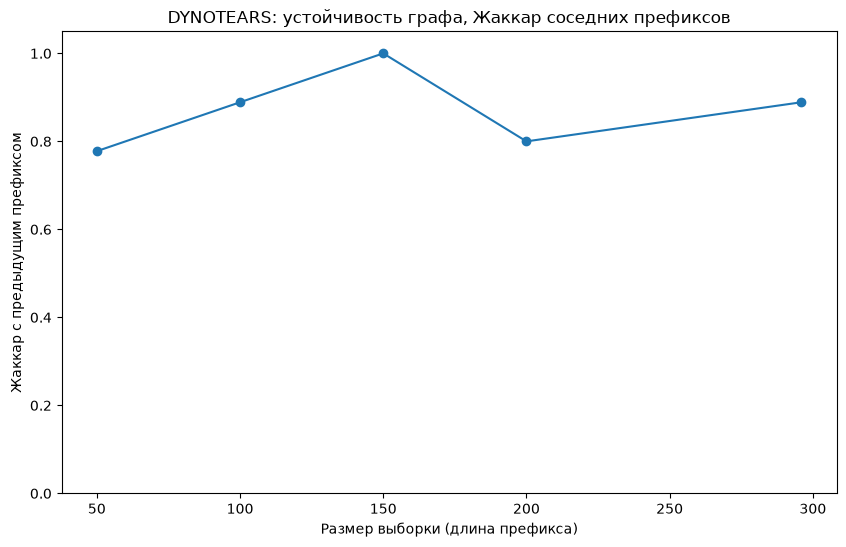

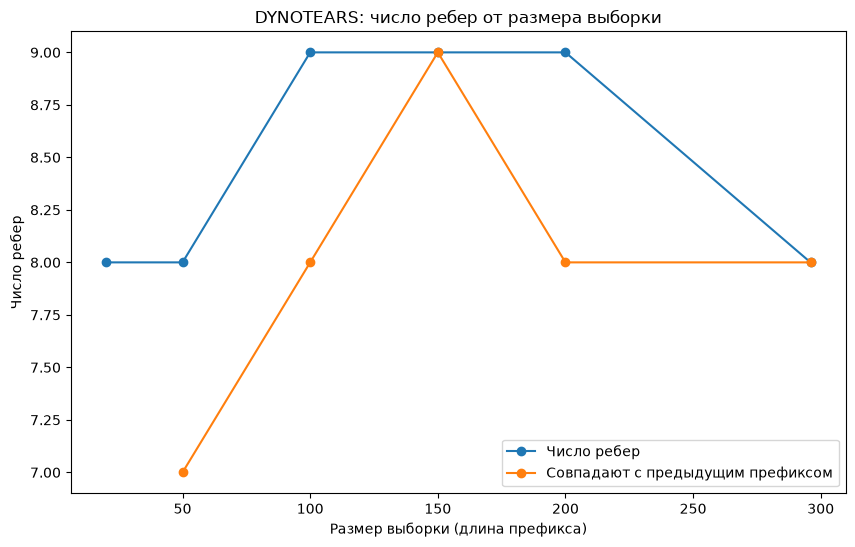

In [31]:
gas_prefix_analysis("DYNOTEARS", gas_matrices_dynotears, "Вес связи", 2)

## HARTH: причинные графы для разных движений

Датасет [HARTH](https://archive.ics.uci.edu/dataset/779/harth): два трехосевых акселерометра — на пояснице (`back_x`, `back_y`, `back_z`) и на бедре (`thigh_x`, `thigh_y`, `thigh_z`), частота 50 Гц, у каждого отсчета есть метка активности. Возьмем испытуемого S017: у него есть все четыре нужных движения — ходьба (метка 1), бег (2), подъем по лестнице (4) и велосипед сидя (13).

Чтобы граф было удобно читать, берем каждый второй отсчет (25 Гц) и лаги до 2, то есть до 80 мс. Каждую активность режем на непересекающиеся окна по 20 секунд и берем по 4 окна.

In [32]:
# Из архива https://archive.ics.uci.edu/static/public/779/harth.zip взят файл испытуемого S017, он лежит в папке harth рядом с ноутбуком
harth = pd.read_csv("harth/S017.csv")
harth_names = ["back_x", "back_y", "back_z", "thigh_x", "thigh_y", "thigh_z"]
activities = {1: "Ходьба", 2: "Бег", 4: "Подъем по лестнице", 13: "Велосипед"}

# Каждый второй отсчет: 25 Гц
step = 2
# Окно 500 отсчетов = 20 секунд
harth_win = 500
n_harth_windows = 4

labels = harth["label"].values
harth_values = harth[harth_names].values
# Границы непрерывных кусков с одной меткой
change = np.flatnonzero(np.diff(labels)) + 1
seg_starts = np.r_[0, change]
seg_ends = np.r_[change, len(labels)]

harth_windows = {}
for code, name in activities.items():
    windows = []
    for s, e in zip(seg_starts, seg_ends):
        if labels[s] != code:
            continue
        part = harth_values[s:e:step]
        for k in range(len(part) // harth_win):
            windows.append(part[k * harth_win:(k + 1) * harth_win])
    harth_windows[name] = windows[:n_harth_windows]
    print(f"{name}: всего окон по 20 с = {len(windows)}, берем {len(harth_windows[name])}")

Ходьба: всего окон по 20 с = 15, берем 4
Бег: всего окон по 20 с = 4, берем 4
Подъем по лестнице: всего окон по 20 с = 4, берем 4
Велосипед: всего окон по 20 с = 4, берем 4


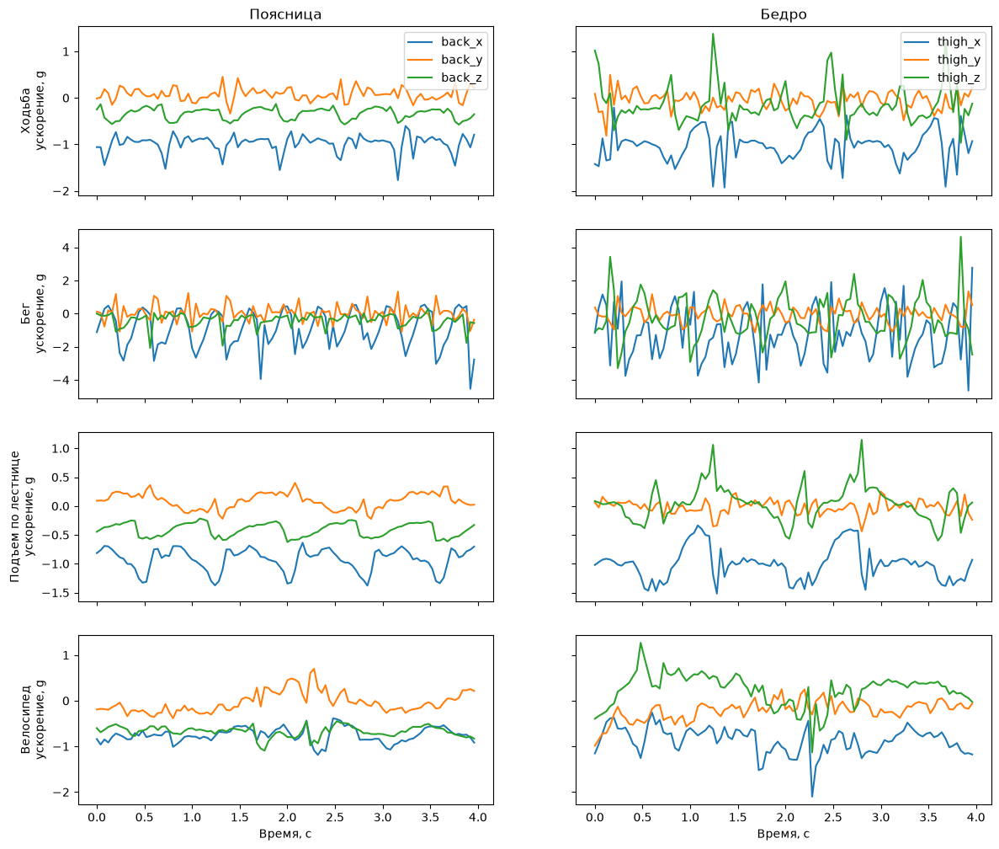

In [38]:
# Первые 4 секунды первого окна каждой активности
t = np.arange(100) / 25
fig, axes = plt.subplots(len(activities), 2, figsize=(14, 12), sharex=True, sharey="row")
for k, name in enumerate(harth_windows):
    W = harth_windows[name][0]
    for c in range(3):
        axes[k, 0].plot(t, W[:100, c], label=harth_names[c])
        axes[k, 1].plot(t, W[:100, 3 + c], label=harth_names[3 + c])
    axes[k, 0].set_ylabel(f"{name}\nускорение, g")
axes[0, 0].set_title("Поясница")
axes[0, 1].set_title("Бедро")
axes[0, 0].legend(loc="upper right")
axes[0, 1].legend(loc="upper right")
axes[-1, 0].set_xlabel("Время, с")
axes[-1, 1].set_xlabel("Время, с")
plt.show()

In [41]:
harth_lags = 2
# Порог выше, чем для ЭЭГ, иначе у VARLiNGAM получается 20+ ребер и граф не читается
harth_threshold = 0.3

# Каналы в разных единицах и с очень разным разбросом (на велосипеде поясница почти неподвижна), поэтому каждое окно стандартизуем
def harth_std(X_part):
    return (X_part - X_part.mean(axis=0)) / X_part.std(axis=0)

def harth_matrices_varlingam(X_part):
    model = VARLiNGAM(lags=harth_lags, criterion=None, prune=True, random_state=42)
    model.fit(harth_std(X_part))
    B_part = model.adjacency_matrices_
    return [B_part[tau].T for tau in range(B_part.shape[0])]

def harth_matrices_pcmci(X_part):
    data_part = pp.DataFrame(harth_std(X_part), var_names=harth_names)
    model = PCMCI(dataframe=data_part, cond_ind_test=ParCorr(significance="analytic"), verbosity=0)
    results = model.run_pcmciplus(tau_min=0, tau_max=harth_lags, pc_alpha=0.05)
    M = np.where(results["graph"] == "-->", results["val_matrix"], 0)
    return [M[:, :, tau] for tau in range(M.shape[2])]

def harth_matrices_dynotears(X_part):
    return dynotears(harth_std(X_part), lags=harth_lags, lambda_w=0.05, lambda_a=0.05, w_threshold=harth_threshold)

harth_models = {"VARLiNGAM": harth_matrices_varlingam, "PCMCI+": harth_matrices_pcmci, "DYNOTEARS": harth_matrices_dynotears}

# harth_fits[метод][активность] — список матриц по окнам
harth_fits = {m: {a: [harth_models[m](W) for W in harth_windows[a]] for a in activities.values()} for m in harth_models}

Граф каждой активности — модель, обученная на первом 20-секундном окне. Сначала, как раньше, граф, развернутый по времени: вершины — каналы в моменты $t-2$, $t-1$, $t$.

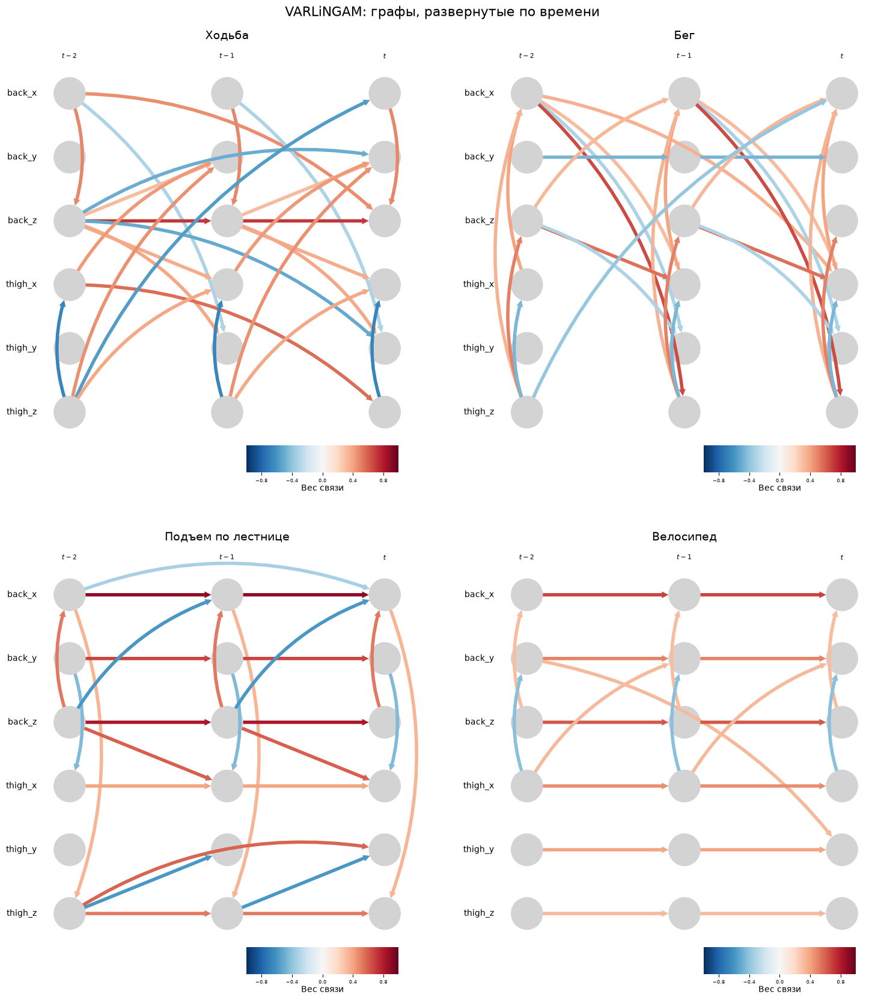

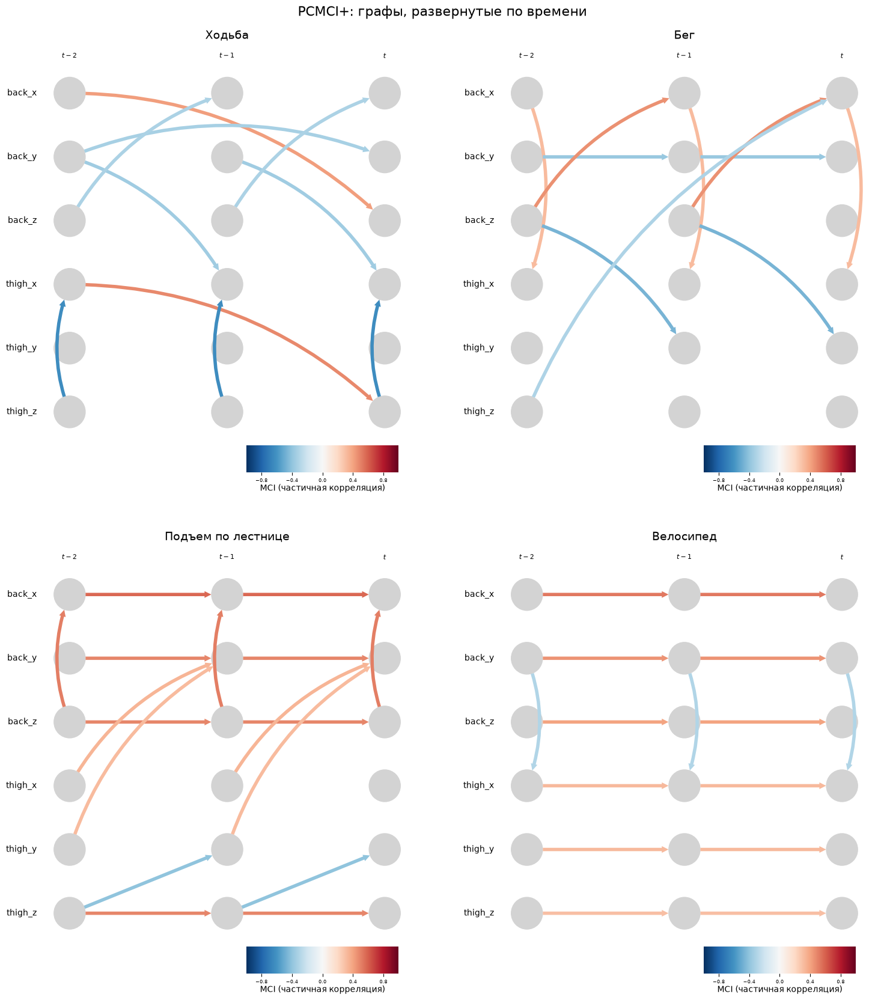

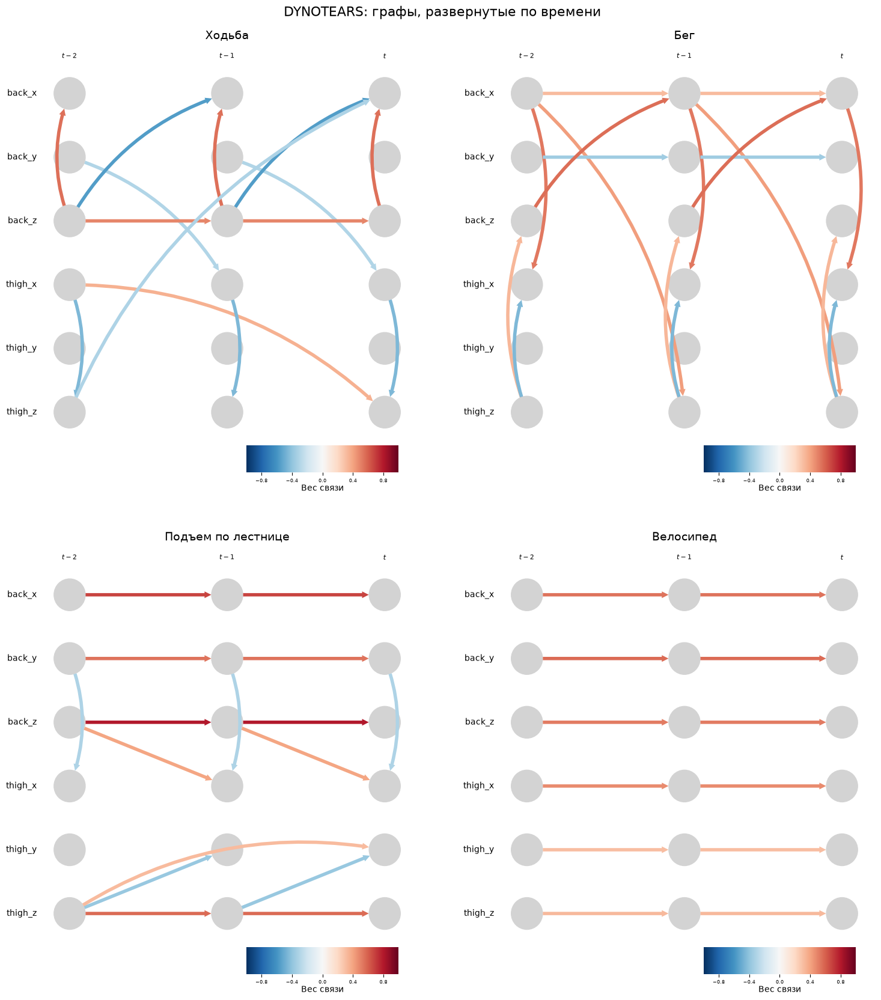

In [42]:
harth_link_labels = {"VARLiNGAM": "Вес связи", "PCMCI+": "MCI (частичная корреляция)", "DYNOTEARS": "Вес связи"}

for m in harth_models:
    fig, axes = plt.subplots(2, 2, figsize=(18, 18))
    axes = axes.reshape(-1)
    for k, name in enumerate(activities.values()):
        graph_k, val_k = to_tigramite(harth_fits[m][name][0], harth_threshold)
        tp.plot_time_series_graph(
            graph=graph_k,
            val_matrix=val_k,
            var_names=harth_names,
            fig_ax=(fig, axes[k]),
            link_colorbar_label=harth_link_labels[m]
        )
        axes[k].set_title(name, pad=25, fontsize=14)
    fig.subplots_adjust(hspace=0.3, top=0.93)
    fig.suptitle(f"{m}: графы, развернутые по времени", fontsize=16)
    plt.show()

Тот же граф можно свернуть по времени: каждый канал — одна вершина, а связи со всех лагов рисуются между этими вершинами (сводный граф). Узлы поясницы сверху, бедра снизу. Прямая стрелка — мгновенная связь (лаг 0), изогнутая — связь с запаздыванием, числа на ней — лаги. Цвет узла — связь ряда с собственным прошлым (на развернутом графе это стрелки из канала в него же).

Из-за того, что лаги склеены, на сводном графе бывают циклы из двух вершин. Например, у VARLiNGAM на ходьбе есть `thigh_z → thigh_x` на лаге 0 и `thigh_x → thigh_z` на лаге 2. На развернутом графе это ребра `thigh_z(t) → thigh_x(t)` и `thigh_x(t-2) → thigh_z(t)`: цепочка `thigh_x(t-2) → thigh_z(t) → thigh_x(t)` идет вперед по времени и в исходную вершину не возвращается. Запрещены только циклы внутри одного момента времени, то есть на лаге 0.

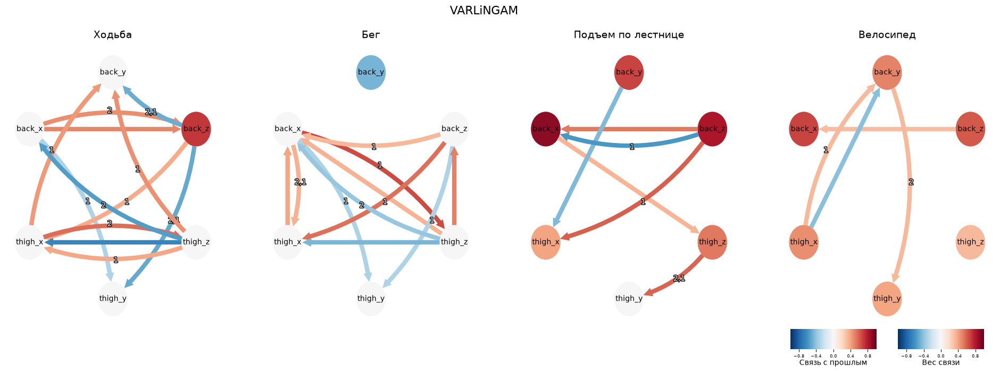

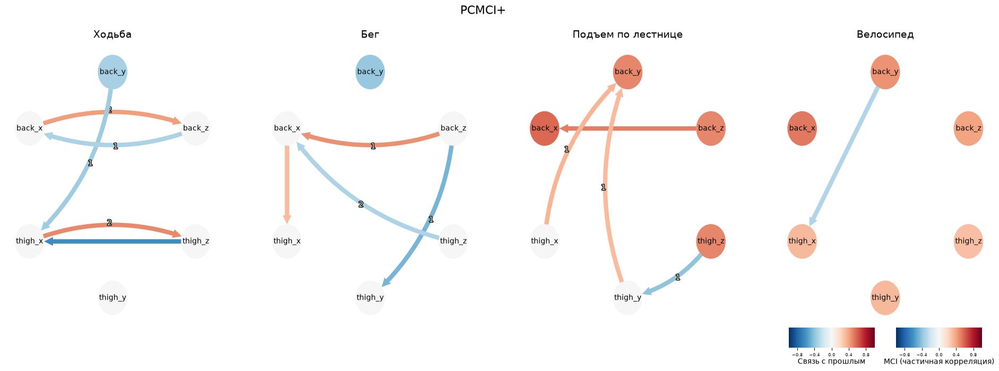

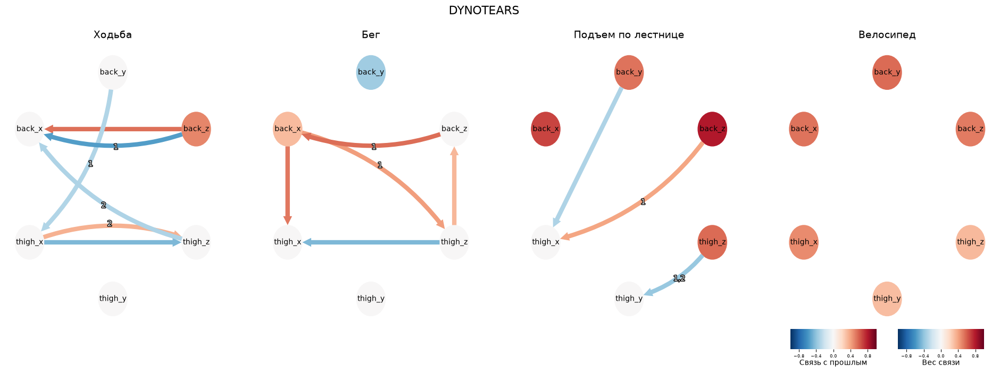

In [43]:
# Узлы по шестиугольнику: поясница сверху, бедро снизу, так ребра не проходят через соседние узлы
angles = np.deg2rad([150, 90, 30, 210, 270, 330])
harth_pos = {"x": np.cos(angles), "y": np.sin(angles)}

for m in harth_models:
    fig, axes = plt.subplots(1, len(activities), figsize=(24, 7))
    for k, name in enumerate(activities.values()):
        graph_k, val_k = to_tigramite(harth_fits[m][name][0], harth_threshold)
        tp.plot_graph(
            graph=graph_k,
            val_matrix=val_k,
            var_names=harth_names,
            fig_ax=(fig, axes[k]),
            node_pos=harth_pos,
            node_size=0.3,
            node_aspect=1,
            arrow_linewidth=6,
            # Шкалы одинаковые на всех панелях, рисуем их только на последней
            show_colorbar=(k == len(activities) - 1),
            link_colorbar_label=harth_link_labels[m],
            node_colorbar_label="Связь с прошлым"
        )
        axes[k].set_title(name, fontsize=14)
    fig.suptitle(m, fontsize=16)
    plt.show()

Проверим это на всех 16 окнах: в развернутом графе (вершины — каналы в моменты $t-2$, $t-1$, $t$) циклов быть не должно, а в сводном они могут появиться.

In [6]:
# Развернутый граф: вершина (канал, k) — канал в момент t - k, ребро на лаге tau идет из момента t - k - tau в момент t - k
def unrolled_graph(matrices):
    G = nx.DiGraph()
    for k in range(harth_lags + 1):
        for tau in range(len(matrices)):
            if k + tau > harth_lags:
                continue
            for i, j in np.argwhere(np.abs(matrices[tau]) >= harth_threshold):
                if tau > 0 or i != j:
                    G.add_edge((harth_names[i], k + tau), (harth_names[j], k))
    return G

# Сводный граф: вершина — канал, лаги склеены, петли не учитываем
def summary_graph(matrices):
    G = nx.DiGraph()
    for tau in range(len(matrices)):
        for i, j in np.argwhere(np.abs(matrices[tau]) >= harth_threshold):
            if i != j:
                G.add_edge(harth_names[i], harth_names[j])
    return G

rows = []
for m in harth_models:
    fits = [M for name in activities.values() for M in harth_fits[m][name]]
    rows.append({"Метод": m,
                 "Окон": len(fits),
                 "Окон с циклом в развернутом графе": sum(not nx.is_directed_acyclic_graph(unrolled_graph(M)) for M in fits),
                 "Окон с циклом в сводном графе": sum(not nx.is_directed_acyclic_graph(summary_graph(M)) for M in fits)})
pd.DataFrame(rows)

,Метод,Окон,Окон с циклом в развернутом графе,Окон с циклом в сводном графе
0,VARLiNGAM,16,0,11
1,PCMCI+,16,0,4
2,DYNOTEARS,16,0,5


Может быть, графы просто шумят от окна к окну (как было с ЭЭГ), и разница между движениями случайная? Сравним по Жаккару графы всех 16 окон между собой (ребро — тройка (откуда, куда, лаг), петли не учитываем). Если граф действительно определяется движением, окна одной активности должны быть похожи сильнее, чем окна разных активностей.

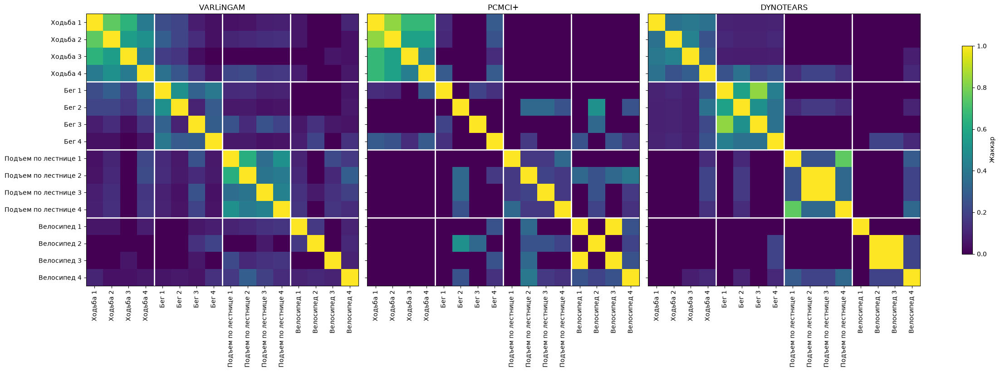

,Метод,Среднее число ребер,Жаккар внутри активности,Жаккар между активностями
0,VARLiNGAM,9.3,0.35,0.09
1,PCMCI+,3.4,0.29,0.07
2,DYNOTEARS,3.9,0.40,0.06


In [44]:
def harth_edges(matrices):
    edges = set()
    for tau in range(len(matrices)):
        for i, j in np.argwhere(np.abs(matrices[tau]) >= harth_threshold):
            if i != j:
                edges.add((harth_names[i], harth_names[j], tau))
    return edges

window_labels = [f"{name} {k + 1}" for name in activities.values() for k in range(n_harth_windows)]
window_activity = np.repeat(np.arange(len(activities)), n_harth_windows)

fig, axes = plt.subplots(1, len(harth_models), figsize=(22, 8), sharey=True, constrained_layout=True)
rows = []
for ax, m in zip(axes, harth_models):
    E = [harth_edges(M) for name in activities.values() for M in harth_fits[m][name]]
    J = np.array([[jaccard(a, b) for b in E] for a in E])
    im = ax.imshow(J, cmap="viridis", vmin=0, vmax=1)
    ax.set_xticks(range(len(E)))
    ax.set_xticklabels(window_labels, rotation=90)
    ax.set_yticks(range(len(E)))
    ax.set_yticklabels(window_labels)
    # Границы блоков активностей
    for b in range(1, len(activities)):
        ax.axhline(b * n_harth_windows - 0.5, color="white", lw=2)
        ax.axvline(b * n_harth_windows - 0.5, color="white", lw=2)
    ax.set_title(m)

    upper = np.triu_indices(len(E), k=1)
    same = window_activity[upper[0]] == window_activity[upper[1]]
    rows.append({"Метод": m,
                 "Среднее число ребер": round(np.mean([len(e) for e in E]), 1),
                 "Жаккар внутри активности": round(J[upper][same].mean(), 2),
                 "Жаккар между активностями": round(J[upper][~same].mean(), 2)})
fig.colorbar(im, ax=axes, shrink=0.7, label="Жаккар")
plt.show()

pd.DataFrame(rows)

Какие ребра устойчиво есть у каждой активности — то есть найдены хотя бы в 3 окнах из 4:

In [45]:
def stable_edges(m, name, min_count=3):
    counts = {}
    for M in harth_fits[m][name]:
        for edge in harth_edges(M):
            counts[edge] = counts.get(edge, 0) + 1
    edges = sorted(edge for edge, c in counts.items() if c >= min_count)
    return ", ".join(f"{s} → {t} ({lag})" for s, t, lag in edges)

pd.set_option("display.max_colwidth", None)
rows = [{"Активность": name, "Метод": m, "Ребра (лаг)": stable_edges(m, name)} for name in activities.values() for m in harth_models]
pd.DataFrame(rows)

,Активность,Метод,Ребра (лаг)
0,Ходьба,VARLiNGAM,"back_x → back_z (0), back_x → back_z (2), back_x → thigh_y (1), back_z → back_y (2), back_z → thigh_x (1), back_z → thigh_y (1), back_z → thigh_y (2), thigh_x → thigh_z (2), thigh_z → back_x (2), thigh_z → back_y (1), thigh_z → thigh_x (0)"
1,Ходьба,PCMCI+,"back_x → back_z (2), back_y → thigh_x (1), back_z → back_x (1), thigh_x → thigh_z (2), thigh_z → thigh_x (0)"
2,Ходьба,DYNOTEARS,"back_z → back_x (0), back_z → back_x (1), thigh_x → thigh_z (0), thigh_x → thigh_z (2)"
3,Бег,VARLiNGAM,"back_x → thigh_x (2), back_x → thigh_z (1), back_z → thigh_x (1), thigh_x → back_x (0), thigh_z → back_x (0), thigh_z → back_z (0)"
4,Бег,PCMCI+,
5,Бег,DYNOTEARS,"back_x → thigh_x (0), back_x → thigh_z (1), back_z → back_x (1), thigh_z → thigh_x (0)"
6,Подъем по лестнице,VARLiNGAM,"back_y → thigh_x (0), back_z → back_x (0), back_z → back_x (1), back_z → thigh_x (1), thigh_z → thigh_y (1), thigh_z → thigh_y (2)"
7,Подъем по лестнице,PCMCI+,back_z → thigh_x (1)
8,Подъем по лестнице,DYNOTEARS,back_z → thigh_x (1)
9,Велосипед,VARLiNGAM,thigh_x → back_y (0)


## Сравнение с кластеризацией из статьи Грабового

В статье Grabovoy, Strijov [«Quasi-periodic time series clustering for human activity recognition»](https://m1p.org/papers/Grabovoy2019QuasiPeriodicTimeSeries.pdf) размечаются точки ряда акселерометра телефона, в котором человек меняет вид движения. Точка $t$ описывается базисом PCA локальной фазовой траектории по отсчетам $[t-2T,\ t+T)$, между точками считается расстояние между базисами, и точки делятся на $K=2$ кластера (`AgglomerativeClustering`, complete). Качество — доля неверно размеченных точек $S$ из Table 1, то есть точность $1-S$. Это кластеризация: разметка при обучении не используется.

Возьмем те же 4 реальных ряда из [репозитория автора](https://github.com/andriygav/TimeSeriesClustering) и сделаем то же самое, но точку $t$ опишем причинным графом: на тех же отсчетах $[t-2T,\ t+T)$ обучим VARLiNGAM, PCMCI+ и DYNOTEARS по трем осям акселерометра. Расстояние между точками — евклидово расстояние между весами всех ребер развернутого графа (лаги 0, 1, 2). Кластеризация, $T$ и метрика — как в статье.

В статье берется одна ось акселерометра, а граф на одной переменной не построить, поэтому из исходных записей `RealData` берем те же строки, но все три оси.

In [2]:
import sys
from joblib import Parallel, delayed
from scipy.spatial.distance import pdist, squareform
from sklearn.cluster import AgglomerativeClustering

# Из репозитория https://github.com/andriygav/TimeSeriesClustering взяты code/lib.py, code/RealData и code/ExperimentData, они лежат в папке grabovoy рядом с ноутбуком
sys.path.append("grabovoy")
import lib

# Как автор получил ряды ExperimentData из записей RealData (восстановлено сравнением файлов):
# (имя в Table 1 статьи, файл ExperimentData, файл RealData, строки, ось в статье, интерполяция на равномерную сетку, T, S в статье)
# В репозитории Physical Motion 1 и 2 подписаны наоборот, со статьей сопоставляем по T и S
grab_series = [
    ("Physical Motion 1", 1, 2, (100, 1000), "Y", False, 50, 0.03),
    ("Physical Motion 2", 2, 1, (100, 1000), "Y", False, 35, 0.08),
    ("Physical Motion 3", 9, 3, (100, 1000), "Y", True, 30, 0.09),
    ("Physical Motion 4", 10, 4, (100, 900), "X", True, 50, 0.01),
]
grab_axes = ["X", "Y", "Z"]

grab_data = {}
for name, exp, real, (start, end), axis, interp, T_paper, S_paper in grab_series:
    experiment = pd.read_csv(f"grabovoy/ExperimentData/{exp}.csv")
    raw = pd.read_csv(f"grabovoy/RealData/{real}.csv").values[start:end]
    if interp:
        X3 = np.column_stack([lib.normalizer(raw[:, c], raw[:, 0], len(raw)) for c in (1, 2, 3)])
    else:
        X3 = raw[:, 1:4]
    # Ось из статьи должна совпасть с рядом из ExperimentData
    assert np.allclose(X3[:, grab_axes.index(axis)], experiment["x"].values)
    grab_data[name] = {"X": X3, "y": experiment["y"].values.astype(int), "axis": axis, "T": T_paper, "S": S_paper}
    print(f"{name}: N = {len(X3)}, T = {T_paper}, смена движения в точках {(np.flatnonzero(np.diff(grab_data[name]['y'])) + 1).tolist()}")

Physical Motion 1: N = 900, T = 50, смена движения в точках [584]
Physical Motion 2: N = 900, T = 35, смена движения в точках [340, 650]
Physical Motion 3: N = 900, T = 30, смена движения в точках [334, 610]
Physical Motion 4: N = 800, T = 50, смена движения в точках [350]


In [3]:
# Метод из статьи — код автора из lib.py
def grabovoy_predict(x, T):
    phase_track = lib.return_phase_track(x.reshape([1, -1, 1]), T)
    basis, singular_values, last_points = lib.local_basis(phase_track, T=T)
    M = lib.get_pairwise_matrix(basis, singular_values, last_points)
    return AgglomerativeClustering(n_clusters=2, metric="precomputed", linkage="complete").fit_predict(M)

def grab_std(X_part):
    return (X_part - X_part.mean(axis=0)) / X_part.std(axis=0)

def grab_matrices_varlingam(X_part):
    model = VARLiNGAM(lags=2, criterion=None, prune=True, random_state=42)
    model.fit(grab_std(X_part))
    B_part = model.adjacency_matrices_
    return [B_part[tau].T for tau in range(B_part.shape[0])]

def grab_matrices_pcmci(X_part):
    data_part = pp.DataFrame(grab_std(X_part), var_names=grab_axes)
    model = PCMCI(dataframe=data_part, cond_ind_test=ParCorr(significance="analytic"), verbosity=0)
    results = model.run_pcmciplus(tau_min=0, tau_max=2, pc_alpha=0.05)
    M = np.where(results["graph"] == "-->", results["val_matrix"], 0)
    return [M[:, :, tau] for tau in range(M.shape[2])]

# Порог не ставим: для расстояния между графами нужны веса, лишние ребра и так зануляет L1-штраф
def grab_matrices_dynotears(X_part):
    return dynotears(grab_std(X_part), lags=2, lambda_w=0.05, lambda_a=0.05, w_threshold=0)

grab_models = {"VARLiNGAM": grab_matrices_varlingam, "PCMCI+": grab_matrices_pcmci, "DYNOTEARS": grab_matrices_dynotears}

# Веса всех ребер развернутого графа на лагах 0, 1, 2 (на лаге 0 петель нет)
grab_mask = np.ones((3, 3, 3), dtype=bool)
grab_mask[0][np.eye(3, dtype=bool)] = False

# Точка t описывается графом на тех же отсчетах [t - 2T, t + T), что и в статье
def causal_predict(get_matrices, X3, T):
    windows = [X3[t - 2 * T:t + T] for t in range(2 * T, len(X3) - T)]
    # Окна независимы, поэтому считаем параллельно
    matrices = np.array(Parallel(n_jobs=-1)(delayed(get_matrices)(W) for W in windows))
    D = squareform(pdist(matrices[:, grab_mask]))
    return AgglomerativeClustering(n_clusters=2, metric="precomputed", linkage="complete").fit_predict(D)

# Точность как в статье: 1 - S по точкам t из [2T, N - T), метки кластеров переименовываются в порядке появления
def grab_accuracy(pred, y, T):
    return 1 - (lib.sort_prediction(pred.copy()) != y[2 * T:len(y) - T]).mean()

# Считаем для T из статьи и соседних значений, чтобы потом проверить устойчивость (несколько минут)
grab_T_grid = [30, 35, 40, 45, 50]
grab_methods = ["Грабовой"] + list(grab_models)
grab_pred = {}
for name, d in grab_data.items():
    for T_win in grab_T_grid:
        grab_pred[name, T_win] = {"Грабовой": grabovoy_predict(d["X"][:, grab_axes.index(d["axis"])], T_win)}
        for m, f in grab_models.items():
            grab_pred[name, T_win][m] = causal_predict(f, d["X"], T_win)

Точность при $T$ из статьи. Метод Грабового посчитан кодом автора (`lib.py`) и воспроизводит Table 1 с точностью до 0.01.

In [4]:
rows = []
for name, d in grab_data.items():
    row = {"Ряд": f"{name} (T = {d['T']})", "В статье, 1 - S": 1 - d["S"]}
    for m in grab_methods:
        row[m] = grab_accuracy(grab_pred[name, d["T"]][m], d["y"], d["T"])
    rows.append(row)
grab_table = pd.DataFrame(rows).set_index("Ряд")
grab_table.loc["Среднее"] = grab_table.mean()
grab_table.round(3)

,"В статье, 1 - S",Грабовой,VARLiNGAM,PCMCI+,DYNOTEARS
Ряд,,,,,
Physical Motion 1 (T = 50),0.970,0.967,0.952,0.735,0.779
Physical Motion 2 (T = 35),0.920,0.926,0.803,0.917,0.961
Physical Motion 3 (T = 30),0.910,0.914,0.701,0.712,0.877
Physical Motion 4 (T = 50),0.990,0.989,0.934,0.965,0.832
Среднее,0.948,0.949,0.847,0.832,0.862


Как размечены точки: сверху ось акселерометра из статьи, снизу полосы — разметка автора и кластеры каждого метода (номера кластеров переименованы в порядке появления, как при подсчете точности). Черные вертикальные линии — смена движения по разметке.

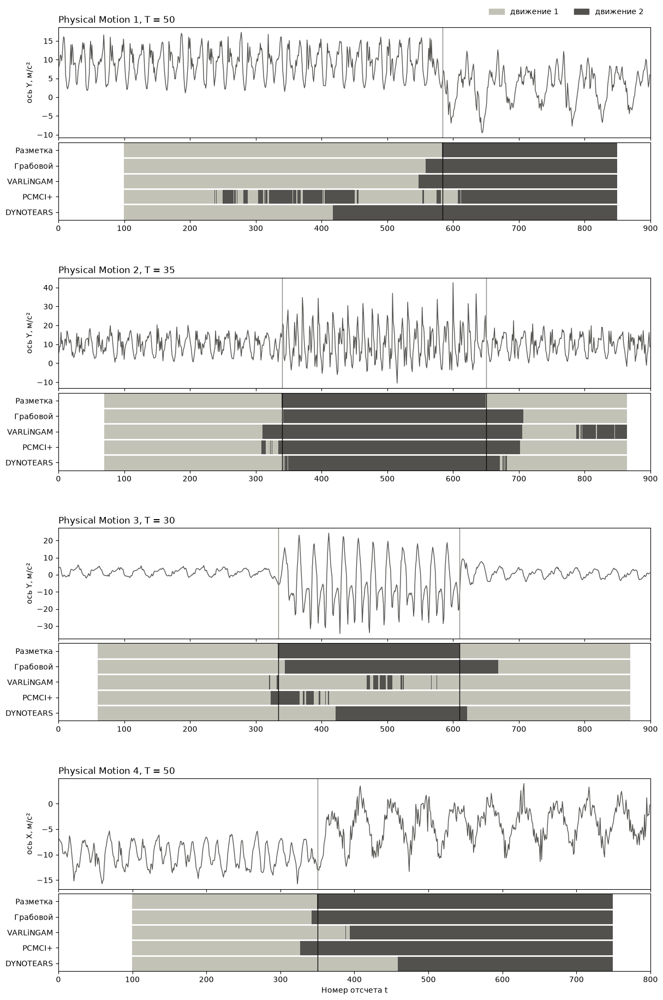

In [5]:
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch

# Классы — два оттенка серого, чтобы не путать с цветами методов на следующем графике
class_colors = ["#c3c2b7", "#52514e"]
strip_names = ["Разметка"] + grab_methods

fig = plt.figure(figsize=(14, 19))
outer = fig.add_gridspec(len(grab_data), 1, hspace=0.3, top=0.95, bottom=0.04)
for k, (name, d) in enumerate(grab_data.items()):
    T_paper = d["T"]
    t = np.arange(2 * T_paper, len(d["y"]) - T_paper)
    change = np.flatnonzero(np.diff(d["y"])) + 1
    inner = outer[k].subgridspec(2, 1, height_ratios=[2, 1.4], hspace=0.05)
    ax_signal = fig.add_subplot(inner[0])
    ax_strip = fig.add_subplot(inner[1], sharex=ax_signal)

    ax_signal.plot(d["X"][:, grab_axes.index(d["axis"])], color="#52514e", lw=1)
    ax_signal.set_xlim(0, len(d["y"]))
    ax_signal.set_ylabel(f"ось {d['axis']}, м/с²")
    ax_signal.set_title(f"{name}, T = {T_paper}", loc="left")
    ax_signal.tick_params(labelbottom=False)

    strips = [d["y"][t]] + [lib.sort_prediction(grab_pred[name, T_paper][m].copy()) for m in grab_methods]
    ax_strip.imshow(np.array(strips), aspect="auto", cmap=ListedColormap(class_colors), vmin=0, vmax=1,
                    interpolation="nearest", extent=[t[0] - 0.5, t[-1] + 0.5, len(strips) - 0.5, -0.5])
    ax_strip.set_yticks(range(len(strips)))
    ax_strip.set_yticklabels(strip_names)
    # Белые промежутки между полосами
    for b in range(1, len(strips)):
        ax_strip.axhline(b - 0.5, color="white", lw=2)
    # Вертикальные линии — точки смены движения по разметке
    for c in change:
        ax_signal.axvline(c, color="#898781", lw=1)
        ax_strip.axvline(c, color="#0b0b0b", lw=1)
    if k == len(grab_data) - 1:
        ax_strip.set_xlabel("Номер отсчета t")

fig.legend(handles=[Patch(color=class_colors[0], label="движение 1"), Patch(color=class_colors[1], label="движение 2")],
           loc="upper right", bbox_to_anchor=(0.9, 0.975), ncol=2, frameon=False)
plt.show()

Результат complete-кластеризации сильно зависит от $T$: даже у метода из статьи ошибка на одном ряду меняется в разы при соседних $T$. Поэтому сравним методы на всей сетке $T$ от 30 до 50. Серая вертикальная линия — $T$ из статьи.

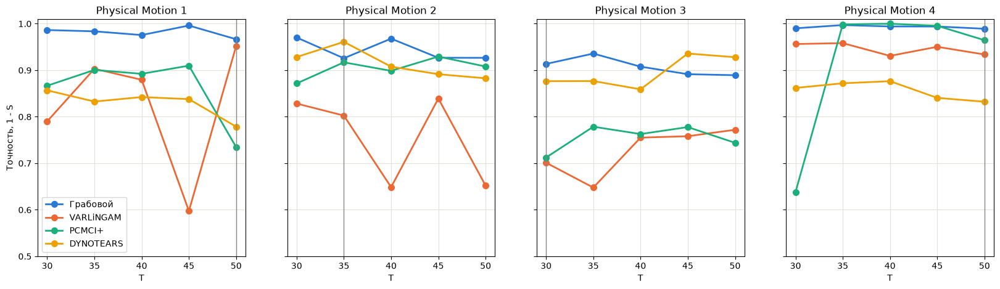

Метод,Грабовой,VARLiNGAM,PCMCI+,DYNOTEARS
Ряд,,,,
Physical Motion 1,0.982,0.824,0.861,0.830
Physical Motion 2,0.944,0.754,0.905,0.914
Physical Motion 3,0.908,0.727,0.755,0.895
Physical Motion 4,0.993,0.946,0.919,0.857
Среднее,0.956,0.813,0.860,0.874


In [6]:
method_colors = {"Грабовой": "#2a78d6", "VARLiNGAM": "#eb6834", "PCMCI+": "#1baf7a", "DYNOTEARS": "#eda100"}

rows = []
fig, axes = plt.subplots(1, len(grab_data), figsize=(20, 5), sharey=True)
for ax, (name, d) in zip(axes, grab_data.items()):
    for m in grab_methods:
        acc = [grab_accuracy(grab_pred[name, T_win][m], d["y"], T_win) for T_win in grab_T_grid]
        ax.plot(grab_T_grid, acc, marker="o", ms=7, lw=2, color=method_colors[m], label=m)
        rows.append({"Ряд": name, "Метод": m, "Средняя точность по T": np.mean(acc)})
    ax.axvline(d["T"], color="#898781", lw=1)
    ax.set_title(name)
    ax.set_xticks(grab_T_grid)
    ax.set_xlabel("T")
    ax.grid(color="#e1e0d9", lw=0.8)
    ax.set_axisbelow(True)
axes[0].set_ylabel("Точность, 1 - S")
axes[0].set_ylim(0.5, 1.01)
axes[0].legend(loc="lower left")
plt.show()

grab_sweep = pd.DataFrame(rows).pivot(index="Ряд", columns="Метод", values="Средняя точность по T")[grab_methods]
grab_sweep.loc["Среднее"] = grab_sweep.mean()
grab_sweep.round(3)